# Viterbi training of the sub-models on their exemplars

Idea for a new `submodel_construction` mode, `all_exemplar_construction_viterbi`:

1. Construct the model as `all_exemplar_construction` does: DTW clusters, then sub-models from each medoid plus its nearest members (`--variance cluster`).
2. Refine it with Viterbi training on the **candidate exemplars** it was built from.

The first notebook (`ViterbiTrainingEffect`) trained on whole recordings, so match states took over background. Exemplars are bounded motif regions, so that shouldn't happen here.

Two assignment modes:

- **free**: every E-step decodes each exemplar against the full model, so exemplars can move to another sub-model (segmental k-means).
- **fixed**: each exemplar stays aligned to the sub-model it decodes to before training. This refines within the clusters the construction found, and a broad sub-model can't take over a small cluster's exemplars.

All code is in the notebook: the training, evaluation and plotting cell below extends the one in `ViterbiTrainingEffect` with exemplar training.

In [1]:
import os
import sys
import glob
import pickle
import numpy as np
REPO = os.path.abspath('..')
sys.path.insert(0, REPO)

In [2]:
import os
import pickle
from collections import Counter
from functools import reduce

import numpy as np
from joblib import Parallel, delayed
from sklearn.mixture import BayesianGaussianMixture

import lib_phmm.profile_hmm as phmm
from lib_phmm.phmm_utils import dwell_to_prior_mean


MATCH_STATE = phmm.MATCH_STATE
B = int(phmm.FlankState.B)
# background states: emit through the noise model when viterbi() gets one, silent otherwise
NOISE_STATES = [int(phmm.FlankState.N), int(phmm.FlankState.J), int(phmm.FlankState.C)]
VAR_FLOOR = 0.1  # same floor compress()/make_hmm()/build_noise_model() apply


# ---------------------------------------------------------------- noise model / decode setup

def fit_noise_model(embeddings, n_components=6, var_floor=VAR_FLOOR, var_scale=1.0, seed=0):
    """
    Same fit as build_noise_model(..., n_components, bayesian=True, var_scale),
    which is what find runs in find and extend mode (handler defaults:
    noise_components=6, noise_var_scale=1.0), from already-embedded noise.
    """
    gmm = BayesianGaussianMixture(n_components=n_components, covariance_type='diag',
                                  init_params='k-means++',
                                  weight_concentration_prior_type='dirichlet_process',
                                  random_state=seed).fit(embeddings)
    active = gmm.weights_ > 1e-3
    components = [phmm.Gaussian(gmm.means_[i], np.maximum(gmm.covariances_[i], var_floor) * var_scale)
                  for i in range(n_components) if active[i]]
    return phmm.MixtureModel(components, np.log(gmm.weights_[active]).tolist())


def noise_params(noise_pdf):
    """(means, variances, log_weights) arrays of a MixtureModel's diagonal Gaussian components."""
    components, log_weights = noise_pdf.__getstate__()
    means, variances = zip(*(c.__getstate__() for c in components))
    return (np.asarray(means, dtype=np.float64), np.asarray(variances, dtype=np.float64),
            np.asarray(log_weights, dtype=np.float64))


def copy_hmm(hmm):
    return pickle.loads(pickle.dumps(hmm))


def with_search_transitions(hmm, repeat_prob=0.999, gap_dwell_frames=100.0):
    """Copy of hmm with find's ec/ej/jj/jb overrides (motif_discovery.apply_search_transitions)."""
    hmm = copy_hmm(hmm)
    jj = dwell_to_prior_mean(gap_dwell_frames)
    hmm.trans.ej = np.log2(repeat_prob)
    hmm.trans.ec = np.log2(1.0 - repeat_prob)
    hmm.trans.jj = np.log2(jj)
    hmm.trans.jb = np.log2(1.0 - jj)
    return hmm


# ---------------------------------------------------------------- map

def summarize(keys, x):
    """Per distinct key: (count, mean, M2) of the rows of x carrying it, as {key: value} dicts."""
    ids, inv = np.unique(keys, return_inverse=True)
    counts = np.bincount(inv, minlength=len(ids)).astype(np.float64)
    sums = np.zeros((len(ids), x.shape[1]))
    np.add.at(sums, inv, x)
    means = sums / counts[:, None]
    M2 = np.zeros_like(sums)
    np.add.at(M2, inv, np.square(x - means[inv]))
    ids = ids.tolist()
    return {"count": dict(zip(ids, counts)), "mean": dict(zip(ids, means)), "M2": dict(zip(ids, M2))}


def assign_components(x, means, variances, log_weights):
    """Most likely mixture component per row of x -- the hard (Viterbi) assignment within the noise model."""
    ll = -0.5 * (np.log(2 * np.pi * variances).sum(axis=1)[None, :]
                 + (np.square(x[:, None, :] - means[None]) / variances[None]).sum(axis=2))
    return (ll + log_weights[None, :]).argmax(axis=1)


def stats_mapper(embedding_seq, hmm, noise_pdf=None, require_full_match=False):
    """
    E-step for one sequence: Viterbi-decode it, then collect
      match  per match state: frames emitted (count), their mean and M2
             (sum of squared deviations from that mean)
      noise  the same per noise-model component, over the frames decoded
             as background (N/J/C), each assigned to its most likely
             component. Skips frame 0 (N there carries no emission) and
             the frame where E -> C happens in the same step as a match's
             last frame (viterbi() scores that frame under both).
             Empty without a noise_pdf, where N/J/C are silent.
    plus every (state, next state) transition count on the path. Silent
    B/E collect nothing.
    """
    embedding_seq = np.asarray(embedding_seq)
    score, path = phmm.viterbi(embedding_seq, hmm, noise_pdf, require_full_match)
    states = np.fromiter((p.state for p in path), dtype=np.int64, count=len(path))
    times  = np.fromiter((p.time for p in path), dtype=np.int64, count=len(path))
    return path_stats(embedding_seq, score, states, times, noise_pdf)


def path_stats(embedding_seq, score, states, times, noise_pdf=None):
    """stats_mapper()'s bookkeeping for one decoded path (states/times arrays, global state ids)."""
    transitions = Counter(zip(states[:-1].tolist(), states[1:].tolist()))

    is_match = states >= MATCH_STATE
    match = summarize(states[is_match], embedding_seq[times[is_match]].astype(np.float64))

    noise = {"count": {}, "mean": {}, "M2": {}}
    if noise_pdf is not None:
        is_noise = np.isin(states, NOISE_STATES) & (times > 0) & ~np.isin(times, times[is_match])
        x = embedding_seq[np.unique(times[is_noise])].astype(np.float64)
        if len(x):
            noise = summarize(assign_components(x, *noise_params(noise_pdf)), x)

    return {
        "score": score,
        "frames": len(embedding_seq),
        "match_frames": int(is_match.sum()),
        "transitions": transitions,
        "match": match,
        "noise": noise,
    }


# ---------------------------------------------------------------- reduce

def chan_merge(count_a, mean_a, M2_a, count_b, mean_b, M2_b):
    """Chan et al. parallel merge of two (count, mean, M2) summaries."""
    count = count_a + count_b
    delta = mean_b - mean_a
    mean = mean_a + delta * (count_b / count)
    M2 = M2_a + M2_b + np.square(delta) * (count_a * count_b / count)
    return count, mean, M2


def merge_summaries(a, b):
    count, mean, M2 = dict(a['count']), dict(a['mean']), dict(a['M2'])
    for key, count_b in b['count'].items():
        if key in count:
            count[key], mean[key], M2[key] = chan_merge(count[key], mean[key], M2[key],
                                                        count_b, b['mean'][key], b['M2'][key])
        else:
            count[key], mean[key], M2[key] = count_b, b['mean'][key], b['M2'][key]
    return {"count": count, "mean": mean, "M2": M2}


def merge_stats(stats_a, stats_b):
    return {
        "score": stats_a['score'] + stats_b['score'],
        "frames": stats_a['frames'] + stats_b['frames'],
        "match_frames": stats_a['match_frames'] + stats_b['match_frames'],
        "transitions": stats_a['transitions'] + stats_b['transitions'],
        "match": merge_summaries(stats_a['match'], stats_b['match']),
        "noise": merge_summaries(stats_a['noise'], stats_b['noise']),
    }


def map_reduce(chunks, hmm, noise_pdf=None, require_full_match=False):
    """One worker's share: map every chunk and combine locally, so only one summary goes back."""
    return reduce(merge_stats, (stats_mapper(c, hmm, noise_pdf, require_full_match) for c in chunks))


# ---------------------------------------------------------------- M-step

def update_gaussian(mu0, var0, summary, key, tau, learning_rate):
    """
    MAP mean/variance for one Gaussian: its aligned frames pooled with tau
    pseudo-frames drawn from the current Gaussian, then moved only
    learning_rate of the way there (the moment-matched mix of (1 - rate)
    current and rate estimated Gaussian), floored at VAR_FLOOR.
    """
    total, mean, M2 = chan_merge(tau, mu0, tau * var0,
                                 summary['count'][key], summary['mean'][key], summary['M2'][key])
    var = np.maximum(M2 / total, VAR_FLOOR)
    if learning_rate < 1:
        _, mean, var = chan_merge(1 - learning_rate, mu0, (1 - learning_rate) * var0,
                                  learning_rate, mean, learning_rate * var)
    return mean, np.maximum(var, VAR_FLOOR)


def check_learning_rate(learning_rate):
    if not 0 < learning_rate <= 1:
        raise ValueError(f"learning_rate must be in (0, 1], got {learning_rate}")


def m_step(hmm, stats, tau=10.0, self_alpha=10.0, entry_alpha=10.0, learning_rate=1.0):
    """
    MAP re-estimation of the motif model from the merged Viterbi
    statistics, each parameter shrunk towards its current value so
    rarely-visited states stay put:

      emissions  every real match state (1 <= k <= last_match[n]) of every
                 sub-model, via update_gaussian(). Unvisited states, the M0
                 sentinel and padding keep their current Gaussians.
      mm         per match state, P(self) from self vs. leaving counts with
                 a Beta prior of weight self_alpha centered on the current
                 value.
      b_to_hmm   per sub-model, entry distribution from B->M[n][k] counts
                 with a Dirichlet prior of weight entry_alpha centered on
                 the current row.

    learning_rate in (0, 1] then moves each parameter only that fraction
    of the way from its current value to the estimate above (1.0 = the
    full MAP step); probabilities interpolate linearly, so rows still sum
    to 1. Unvisited states and transitions have estimate == current value,
    so they stay exactly where they are at any rate.

    The flank transitions (nn/nb/ec/ej/jj/jb/cc) are copied unchanged:
    find overrides ec/ej/jj/jb anyway, and nn/cc come from train's flank
    dwell prior. Advance (M[k] -> M[k+1]) and exit (M -> E) cost nothing
    in viterbi(), so there's nothing to learn for them.
    """
    check_learning_rate(learning_rate)
    K = len(hmm.pdf[0])
    n_models = len(hmm.pdf)

    pdf = [list(row) for row in hmm.pdf]
    for s in stats['match']['count']:
        n, k = divmod(s - MATCH_STATE, K)
        if not 1 <= k <= hmm.last_match[n]:
            continue
        mu0, var0 = (np.asarray(v, dtype=np.float64) for v in pdf[n][k].__getstate__())
        pdf[n][k] = phmm.Gaussian(*update_gaussian(mu0, var0, stats['match'], s, tau, learning_rate))

    mm = np.exp2(np.asarray(hmm.trans.mm, dtype=np.float64))
    b_to_hmm = np.exp2(np.asarray(hmm.trans.b_to_hmm, dtype=np.float64))
    b_to_hmm /= b_to_hmm.sum(axis=1, keepdims=True)

    self_ct = np.zeros((n_models, K))
    leave_ct = np.zeros((n_models, K))
    entry_ct = np.zeros((n_models, K))
    for (a, b), c in stats['transitions'].items():
        if a >= MATCH_STATE:
            n, k = divmod(a - MATCH_STATE, K)
            (self_ct if a == b else leave_ct)[n, k] += c
        elif a == B and b >= MATCH_STATE:
            n, k = divmod(b - MATCH_STATE, K)
            entry_ct[n, k] += c

    mm_hat = (self_ct + self_alpha * mm) / (self_ct + leave_ct + self_alpha)
    b_hat = (entry_ct + entry_alpha * b_to_hmm) / (entry_ct.sum(axis=1, keepdims=True) + entry_alpha)
    mm = (1 - learning_rate) * mm + learning_rate * mm_hat
    b_to_hmm = (1 - learning_rate) * b_to_hmm + learning_rate * b_hat

    t = hmm.trans
    trans = phmm.FlankTransitions(
        nn=2 ** t.nn, nb=2 ** t.nb, ec=2 ** t.ec, ej=2 ** t.ej,
        jj=2 ** t.jj, jb=2 ** t.jb, cc=2 ** t.cc,
        b_to_hmm=b_to_hmm.tolist(), mm=mm.tolist(),
    )
    return phmm.ProfileHMM(pdf, trans, list(hmm.last_match))


def m_step_noise(noise_pdf, stats, tau=10.0, weight_alpha=10.0, learning_rate=1.0):
    """
    Same MAP + learning-rate update for the background model: each
    mixture component's Gaussian via update_gaussian() from the frames
    hard-assigned to it, and the mixture weights from those assignment
    counts with a Dirichlet prior of weight weight_alpha centered on the
    current weights. Components no frame was assigned to keep their
    Gaussian (their weight still shrinks, since weights sum to 1).
    """
    check_learning_rate(learning_rate)
    means, variances, log_weights = noise_params(noise_pdf)
    # fit_noise_model() drops ~0-weight components without renormalizing, so
    # the weights can sum to slightly under 1 -- keep that total, so a
    # component's mass only moves with data
    weights = np.exp(log_weights)
    total_weight = weights.sum()
    weights /= total_weight

    components = []
    counts = np.zeros(len(weights))
    for c in range(len(weights)):
        mean, var = means[c], variances[c]
        if c in stats['noise']['count']:
            counts[c] = stats['noise']['count'][c]
            mean, var = update_gaussian(mean, var, stats['noise'], c, tau, learning_rate)
        components.append(phmm.Gaussian(mean, var))

    weights_hat = (counts + weight_alpha * weights) / (counts.sum() + weight_alpha)
    weights = total_weight * ((1 - learning_rate) * weights + learning_rate * weights_hat)
    return phmm.MixtureModel(components, np.log(weights).tolist())


# ---------------------------------------------------------------- training loop

def chunked(seq, chunk_frames):
    return [seq[i:i + chunk_frames] for i in range(0, len(seq), chunk_frames) if len(seq[i:i + chunk_frames]) > 1]


def n_states_of(hmm):
    return len(hmm.pdf) * len(hmm.pdf[0]) + MATCH_STATE


def viterbi_memory_gb(hmm, chunk_frames):
    """viterbi()'s DP table W (double) + traceback TB (Pred, two ints): 16 bytes per (frame, state)."""
    return chunk_frames * n_states_of(hmm) * 16 / 1e9


def plan_workers(hmm, n_jobs=None, chunk_frames=None, memory_budget_gb=None):
    """
    Pick n_jobs (default: every core) and chunk_frames so that all workers'
    Viterbi tables fit in memory_budget_gb together (default: half the
    machine's RAM, leaving room for each worker's own copy of the model
    and the OS). Whichever of n_jobs/chunk_frames is given is kept; the
    other is fitted to the budget.
    """
    if memory_budget_gb is None:
        memory_budget_gb = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9 / 2
    per_frame_gb = viterbi_memory_gb(hmm, 1)
    if n_jobs is None:
        n_jobs = os.cpu_count() if chunk_frames is None else max(1, min(
            os.cpu_count(), int(memory_budget_gb / (chunk_frames * per_frame_gb))))
    if chunk_frames is None:
        chunk_frames = max(100, int(memory_budget_gb / (n_jobs * per_frame_gb)))
    print(f"E-step: {n_jobs} workers x {chunk_frames}-frame chunks, "
          f"~{n_jobs * viterbi_memory_gb(hmm, chunk_frames):.1f} GB of Viterbi tables "
          f"(budget {memory_budget_gb:.1f} GB)")
    return n_jobs, chunk_frames


def viterbi_training(hmm, sequences, noise_pdf=None, n_iter=5, chunk_frames=None, n_jobs=None,
                     memory_budget_gb=None, require_full_match=False, repeat_prob=0.999,
                     gap_dwell_frames=100.0, tau=10.0, self_alpha=10.0, entry_alpha=10.0,
                     learning_rate=1.0, update_noise=True, noise_tau=10.0, noise_weight_alpha=10.0,
                     after_m_step=None):
    """
    Alternate E (decode every chunk with find's search transitions, map ->
    reduce) and M n_iter times. The M-step updates the motif model
    (m_step()) and, with update_noise and a noise_pdf, the background
    model too (m_step_noise(), same learning_rate) -- so background
    adapts alongside the match states instead of match states absorbing
    background frames against a fixed noise model.

    The E-step runs in n_jobs worker processes (joblib/loky -- viterbi()
    holds the GIL, so threads wouldn't help). Sequences are cut into
    chunk_frames pieces: viterbi() keeps a length x n_states DP and
    traceback table, so a whole 80k-frame recording would need ~20 GB.
    See plan_workers() for how n_jobs/chunk_frames are fitted to
    memory_budget_gb when not given.

    after_m_step(iteration, hmm, noise_pdf), if given, is called with the
    freshly updated models after every M-step (run_sweep() evaluates
    held-out data there).

    Returns the trained hmm, the (possibly updated) noise_pdf and a
    per-iteration history. history[i] is computed by decoding with the
    models *before* M-step i, so the scores are comparable across
    iterations.
    """
    n_jobs, chunk_frames = plan_workers(hmm, n_jobs, chunk_frames, memory_budget_gb)
    chunks = [c for seq in sequences for c in chunked(np.asarray(seq), chunk_frames)]
    # a few batches per worker: each batch ships its own copy of the model
    # (~40 MB pickled), but more than one keeps fast cores busy while slow ones finish
    n_batches = min(len(chunks), n_jobs * 2)
    batches = [chunks[i::n_batches] for i in range(n_batches)]

    history = []
    for it in range(n_iter):
        decode_hmm = with_search_transitions(hmm, repeat_prob, gap_dwell_frames)
        parts = Parallel(n_jobs=n_jobs)(
            delayed(map_reduce)(b, decode_hmm, noise_pdf, require_full_match) for b in batches)
        stats = reduce(merge_stats, parts)
        noise_counts = stats['noise']['count']
        row = {
            "iteration": it,
            "score_per_frame": stats['score'] / stats['frames'],
            "match_fraction": stats['match_frames'] / stats['frames'],
            "states_visited": len(stats['match']['count']),
            "noise_component_frames": [int(noise_counts[c]) for c in sorted(noise_counts)],
        }
        history.append(row)
        print(f"iter {it}: score/frame {row['score_per_frame']:.3f} bits, "
              f"{100 * row['match_fraction']:.1f}% frames in match states, "
              f"{row['states_visited']} match states visited, "
              f"noise frames per component {row['noise_component_frames']}")
        hmm = m_step(hmm, stats, tau=tau, self_alpha=self_alpha, entry_alpha=entry_alpha,
                     learning_rate=learning_rate)
        if update_noise and noise_pdf is not None:
            noise_pdf = m_step_noise(noise_pdf, stats, tau=noise_tau, weight_alpha=noise_weight_alpha,
                                     learning_rate=learning_rate)
        if after_m_step is not None:
            after_m_step(it, hmm, noise_pdf)
    return hmm, noise_pdf, history


# ---------------------------------------------------------------- evaluation

WHISTLE_LABELS = ('UP', 'DOWN')
TRAIN_GAP_FRAMES = 17      # ~1 s at 58 ms/frame: whistle runs this close are one train (a broken whistle)
FAR_FRAMES = 17            # background frames further than this from any non-NOISE frame
MIN_TRAIN_FRAMES = 5       # labeled frames a train needs to count
FULL_COVER = 0.9           # a train counts as kept whole when one hit covers this much of it
EVAL_COUNTS = ('frames', 'match_frames', 'signal_frames', 'match_on_signal', 'far_frames', 'far_matched',
               'hits', 'hit_frames', 'short_hits',
               'whistle_trains', 'whistle_train_hits', 'whistle_train_cover', 'whistle_trains_whole', 'whistle_trains_missed',
               'signal_trains', 'signal_train_hits', 'signal_train_cover', 'signal_trains_whole', 'signal_trains_missed')


def frame_hits(embedding_seq, hmm, noise_pdf=None, require_full_match=False):
    """
    Viterbi-decode and return (score, hit, submodel): per frame the index
    of the B..E pass (hit) covering it and that hit's sub-model, -1 on
    background frames.
    """
    score, path = phmm.viterbi(embedding_seq, hmm, noise_pdf, require_full_match)
    states = np.fromiter((p.state for p in path), dtype=np.int64, count=len(path))
    times  = np.fromiter((p.time for p in path), dtype=np.int64, count=len(path))
    hit = np.full(len(embedding_seq), -1)
    submodel = np.full(len(embedding_seq), -1)
    is_match = states >= MATCH_STATE
    hit[times[is_match]] = (np.cumsum(states == B) - 1)[is_match]
    submodel[times[is_match]] = (states[is_match] - MATCH_STATE) // len(hmm.pdf[0])
    return score, hit, submodel


def runs(mask):
    """(start, stop) of every run of True in a boolean array."""
    padded = np.concatenate([[False], mask, [False]]).astype(np.int8)
    edges = np.flatnonzero(np.diff(padded))
    return list(zip(edges[::2], edges[1::2]))


def trains(mask, gap_frames=TRAIN_GAP_FRAMES, min_frames=MIN_TRAIN_FRAMES):
    """
    Runs of mask merged across gaps of at most gap_frames -- a whistle
    broken in the middle stays one train -- as (start, stop), keeping
    trains with at least min_frames labeled frames.
    """
    merged = []
    for start, stop in runs(mask):
        if merged and start - merged[-1][1] <= gap_frames:
            merged[-1][1] = stop
        else:
            merged.append([start, stop])
    return [(a, b) for a, b in merged if mask[a:b].sum() >= min_frames]


def train_counts(hit, spans):
    """Over train spans: how many, total distinct hits in them, summed largest-hit coverage, whole, missed."""
    n = total = whole = missed = 0
    cover = 0.0
    for start, stop in spans:
        w = hit[start:stop]
        ids, cnt = np.unique(w[w >= 0], return_counts=True)
        largest = cnt.max() / (stop - start) if len(ids) else 0.0
        n, total, cover = n + 1, total + len(ids), cover + largest
        whole += largest >= FULL_COVER
        missed += len(ids) == 0
    return n, total, cover, whole, missed


def far_from(mask, distance):
    """Frames further than `distance` frames from any True frame of mask."""
    idx = np.flatnonzero(mask)
    if not len(idx):
        return np.ones(len(mask), bool)
    pos = np.arange(len(mask))
    k = np.clip(np.searchsorted(idx, pos), 1, len(idx)) - 1
    nearest = np.minimum(np.abs(pos - idx[k]), np.abs(pos - idx[np.minimum(k + 1, len(idx) - 1)]))
    return nearest > distance


def eval_mapper(embedding_seq, labels, hmm, noise_pdf=None, require_full_match=False, short_hit_frames=10):
    """
    Decode one sequence and count, against the per-frame classifier labels
    cached next to the embeddings (NOISE / ECHO / BURST / UP / DOWN):
      score            Viterbi log2 score
      far_matched      matched frames more than FAR_FRAMES from any
                       non-NOISE frame (far_frames: all such frames) --
                       background absorbed into motifs, without counting
                       the gaps inside a broken whistle against the model
      match_on_signal  non-NOISE frames that got matched (signal_frames: all)
      hits             one per B..E pass; short_hits under short_hit_frames
      whistle trains   UP/DOWN runs merged across gaps up to TRAIN_GAP_FRAMES:
                       distinct hits per train, how much of the train its
                       largest hit covers, trains kept whole (>= FULL_COVER)
      signal trains    the same for runs of any non-NOISE label
    All plain counts, so the reducer just adds them up.
    """
    embedding_seq = np.asarray(embedding_seq)
    labels = np.asarray(labels)
    score, hit, _ = frame_hits(embedding_seq, hmm, noise_pdf, require_full_match)
    matched = hit >= 0
    signal = labels != 'NOISE'
    far = far_from(signal, FAR_FRAMES)
    hit_lengths = np.bincount(hit[matched]) if matched.any() else np.zeros(0, int)
    hit_lengths = hit_lengths[hit_lengths > 0]

    counts = dict(zip(EVAL_COUNTS, (
        len(embedding_seq), int(matched.sum()), int(signal.sum()), int((matched & signal).sum()),
        int(far.sum()), int((matched & far).sum()),
        len(hit_lengths), int(hit_lengths.sum()), int((hit_lengths < short_hit_frames).sum()),
        *train_counts(hit, trains(np.isin(labels, WHISTLE_LABELS))),
        *train_counts(hit, trains(signal)),
    )))
    counts['score'] = score
    return counts


def eval_batch(pairs, hmm, noise_pdf=None, require_full_match=False):
    return reduce(lambda a, b: {k: a[k] + b[k] for k in a},
                  (eval_mapper(seq, lab, hmm, noise_pdf, require_full_match) for seq, lab in pairs))


def eval_metrics(c):
    """Ratios from summed eval_mapper() counts."""
    div = lambda a, b: a / b if b else float('nan')
    return {
        "score_per_frame": div(c['score'], c['frames']),
        "match_fraction": div(c['match_frames'], c['frames']),
        "background_matched": div(c['far_matched'], c['far_frames']),     # frames far from any signal that got matched
        "signal_recall": div(c['match_on_signal'], c['signal_frames']),
        "mean_hit_frames": div(c['hit_frames'], c['hits']),
        "short_hit_fraction": div(c['short_hits'], c['hits']),
        "hits_per_whistle_train": div(c['whistle_train_hits'], c['whistle_trains'] - c['whistle_trains_missed']),
        "whistle_largest_hit_cover": div(c['whistle_train_cover'], c['whistle_trains']),
        "whistle_trains_whole": div(c['whistle_trains_whole'], c['whistle_trains']),
        "hits_per_signal_train": div(c['signal_train_hits'], c['signal_trains'] - c['signal_trains_missed']),
        "signal_largest_hit_cover": div(c['signal_train_cover'], c['signal_trains']),
        "signal_trains_whole": div(c['signal_trains_whole'], c['signal_trains']),
        "whistle_trains": c['whistle_trains'],
        "signal_trains": c['signal_trains'],
    }


def evaluate(hmm, noise_pdf, sequences, labels, chunk_frames, n_jobs, require_full_match=False,
             repeat_prob=0.999, gap_dwell_frames=100.0):
    """Held-out decode with find's search transitions, chunked and parallel like the E-step."""
    decode_hmm = with_search_transitions(hmm, repeat_prob, gap_dwell_frames)
    pairs = [(np.asarray(seq)[i:i + chunk_frames], np.asarray(lab)[i:i + chunk_frames])
             for seq, lab in zip(sequences, labels) for i in range(0, len(seq), chunk_frames)
             if len(seq) - i > 1]
    n_batches = min(len(pairs), n_jobs * 2)
    parts = Parallel(n_jobs=n_jobs)(delayed(eval_batch)(pairs[i::n_batches], decode_hmm, noise_pdf,
                                                        require_full_match) for i in range(n_batches))
    return eval_metrics(reduce(lambda a, b: {k: a[k] + b[k] for k in a}, parts))


def run_sweep(hmm, noise_pdf, train_sequences, heldout_sequences, heldout_labels, configs, n_iter=4,
              n_jobs=None, chunk_frames=None, memory_budget_gb=None, **training_kwargs):
    """
    Train once per config ({name: viterbi_training kwargs, e.g. learning_rate,
    update_noise}) from the same starting models, evaluating on the held-out
    recordings before training and after every M-step. Iteration 0 (the
    untrained model) is evaluated once and shared by all configs.
    Returns a long DataFrame (config, iteration, split (train/heldout),
    metric columns) and {config: (trained hmm, trained noise_pdf)}.
    """
    import pandas as pd
    n_jobs, chunk_frames = plan_workers(hmm, n_jobs, chunk_frames, memory_budget_gb)
    baseline = evaluate(hmm, noise_pdf, heldout_sequences, heldout_labels, chunk_frames, n_jobs)
    rows, trained = [], {}
    for name, kwargs in configs.items():
        print(f"==== {name}")
        rows.append({"config": name, "iteration": 0, "split": "heldout", **baseline})

        def after_m_step(it, trained_hmm, trained_noise_pdf):
            m = evaluate(trained_hmm, trained_noise_pdf, heldout_sequences, heldout_labels, chunk_frames, n_jobs)
            print(f"  held-out after M-step {it}: score/frame {m['score_per_frame']:.3f}, "
                  f"background matched {m['background_matched']:.2f}, "
                  f"hits/whistle train {m['hits_per_whistle_train']:.2f}, "
                  f"largest hit covers {m['whistle_largest_hit_cover']:.2f}")
            rows.append({"config": name, "iteration": it + 1, "split": "heldout", **m})

        trained_hmm, trained_noise_pdf, history = viterbi_training(
            hmm, train_sequences, noise_pdf, n_iter=n_iter, n_jobs=n_jobs, chunk_frames=chunk_frames,
            after_m_step=after_m_step, **{**training_kwargs, **kwargs})
        rows += [{"config": name, "iteration": h['iteration'], "split": "train",
                  "score_per_frame": h['score_per_frame'], "match_fraction": h['match_fraction']}
                 for h in history]
        trained[name] = (trained_hmm, trained_noise_pdf)
    return pd.DataFrame(rows), trained


SWEEP_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # categorical slots 1-4, fixed order
SWEEP_MARKERS = ['o', 's', '^', 'D']
SWEEP_PANELS = [
    ("score_per_frame", "held-out score / frame (bits)", "heldout"),
    ("score_per_frame", "train score / frame (bits)", "train"),
    ("background_matched", "frames >1 s from any signal that are matched", "heldout"),
    ("signal_recall", "non-NOISE frames matched", "heldout"),
    ("hits_per_whistle_train", "hits per whistle train (1 = whole)", "heldout"),
    ("whistle_largest_hit_cover", "whistle train covered by its largest hit", "heldout"),
    ("hits_per_signal_train", "hits per non-NOISE train", "heldout"),
    ("short_hit_fraction", "hits < 10 frames", "heldout"),
]


def plot_sweep(df, panels=None):
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator
    configs = list(dict.fromkeys(df['config']))
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
    for ax, (metric, title, split) in zip(axes.flat, panels or SWEEP_PANELS):
        sub = df[df['split'] == split]
        for i, name in enumerate(configs):
            d = sub[sub['config'] == name].sort_values('iteration')
            ax.plot(d['iteration'], d[metric], color=SWEEP_COLORS[i], marker=SWEEP_MARKERS[i],
                    markersize=6, linewidth=2, label=name)
        ax.set_title(title, fontsize=10, loc='left', color='#0b0b0b')
        ax.set_xlabel('iteration', color='#52514e')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis='y', color='#e6e5e0', linewidth=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(colors='#52514e')
    axes.flat[0].legend(frameon=False, fontsize=9)
    return fig


# ---------------------------------------------------------------- before / after examples

LABEL_COLORS = {'NOISE': '#e6e5e0', 'UP': '#2a78d6', 'DOWN': '#eb6834', 'ECHO': '#1baf7a', 'BURST': '#eda100'}
LABEL_ORDER = ['UP', 'DOWN', 'ECHO', 'BURST', 'NOISE']
HIT_COLOR = '#52514e'
TRAIN_SHADE = '#cde2fb'


def hit_spans(hit, submodel):
    """(start, stop, submodel) of every hit in per-frame arrays, stop exclusive."""
    spans = []
    for start, stop in runs(hit >= 0):
        cuts = [start] + [i for i in range(start + 1, stop) if hit[i] != hit[i - 1]] + [stop]
        spans += [(a, b, int(submodel[a])) for a, b in zip(cuts[:-1], cuts[1:])]
    return spans


def _decode_window(seq, lo, hi, before, after, require_full_match, repeat_prob, gap_dwell_frames):
    out = []
    for hmm, noise_pdf in (before, after):
        _, hit, submodel = frame_hits(seq[lo:hi], with_search_transitions(hmm, repeat_prob, gap_dwell_frames),
                                      noise_pdf, require_full_match)
        out.append((hit, submodel))
    return out


def pick_examples(before, after, sequences, labels, names, n_changed=4, n_random=2, window=300, margin=100,
                  max_candidates=40, n_jobs=4, seed=0, require_full_match=False, repeat_prob=0.999,
                  gap_dwell_frames=100.0):
    """
    Before/after examples on held-out recordings, one per whistle train.
    before/after are (hmm, noise_pdf) pairs. Up to max_candidates whistle
    trains (seeded) are each decoded by both models in a `window`-frame
    window centered on the train, with `margin` extra frames of context on
    each side. Returns the n_changed trains whose decode changed most
    (change in hit count on the train plus change in how much of it the
    largest hit covers) and n_random further trains drawn at random, so
    the set isn't only the most dramatic cases.
    """
    rng = np.random.default_rng(seed)
    pool = [(f, a, b) for f, lab in enumerate(labels) for a, b in trains(np.isin(np.asarray(lab), WHISTLE_LABELS))]
    pool = [pool[i] for i in rng.permutation(len(pool))]

    spans = []
    for f, a, b in pool:                         # skip windows overlapping one already taken
        if len(spans) == max_candidates:
            break
        center, n = (a + b) // 2, len(sequences[f])
        lo = max(0, center - window // 2 - margin)
        hi = min(n, center + window // 2 + margin)
        if not any(g == f and lo < h and l < hi for g, l, h, _, _ in spans):
            spans.append((f, lo, hi, a, b))
    decoded = Parallel(n_jobs=n_jobs)(
        delayed(_decode_window)(np.asarray(sequences[f]), lo, hi, before, after,
                                require_full_match, repeat_prob, gap_dwell_frames)
        for f, lo, hi, _, _ in spans)

    examples = []
    for (f, lo, hi, a, b), ((hit_b, sub_b), (hit_a, sub_a)) in zip(spans, decoded):
        v0 = margin if lo > 0 else 0              # crop the context margin back off
        v1 = min(v0 + window, hi - lo)
        cut = slice(v0, v1)
        lab = np.asarray(labels[f])[lo + v0: lo + v1]
        train_spans = trains(np.isin(lab, WHISTLE_LABELS))
        on_train = slice(a - lo, b - lo)          # the train this window is centered on
        (n_b, tot_b, cov_b, _, _), (n_a, tot_a, cov_a, _, _) = (train_counts(h, [(on_train.start, on_train.stop)])
                                                                for h in (hit_b, hit_a))
        examples.append({
            "name": names[f], "start": lo + v0, "stop": lo + v1, "labels": lab, "trains": train_spans,
            "before": hit_spans(hit_b[cut], sub_b[cut]), "after": hit_spans(hit_a[cut], sub_a[cut]),
            "train_hits": (tot_b, tot_a), "train_cover": (cov_b, cov_a),
            "change": abs(tot_b - tot_a) + 5 * abs(cov_b - cov_a),
        })
    order = sorted(range(len(examples)), key=lambda i: -examples[i]['change'])
    chosen, rest = order[:n_changed], order[n_changed:]
    chosen += [rest[i] for i in rng.choice(len(rest), size=min(n_random, len(rest)), replace=False)]
    for k, i in enumerate(chosen):
        examples[i]['picked'] = 'most changed' if k < n_changed else 'random'
    return [examples[i] for i in chosen]


def example_table(ex, step_seconds):
    """One row per hit, before and after, with the classifier's majority label over the hit's frames."""
    import pandas as pd
    rows = []
    for model in ('before', 'after'):
        for start, stop, sub in ex[model]:
            lab = Counter(ex['labels'][start:stop]).most_common(1)[0]
            rows.append({"model": model, "start_s": round((ex['start'] + start) * step_seconds, 2),
                         "stop_s": round((ex['start'] + stop) * step_seconds, 2), "frames": stop - start,
                         "submodel": sub, "majority_label": lab[0],
                         "majority_fraction": round(lab[1] / (stop - start), 2)})
    return pd.DataFrame(rows)


def load_clip(path, start_s, stop_s):
    """Mono audio between start_s and stop_s (same approach as motif_filtering.ipynb's load_clip)."""
    import librosa
    import soundfile as sf
    start_s = max(0.0, start_s)
    if path.lower().endswith('.wav'):
        sr = sf.info(path).samplerate
        x, sr = sf.read(path, start=int(start_s * sr), stop=int(stop_s * sr), always_2d=True)
        return x.mean(axis=1), sr
    x, sr = librosa.load(path, sr=None, mono=True, offset=start_s, duration=stop_s - start_s)
    return x, sr


def plot_example(ex, step_seconds, audio_path=None, before_label='before', after_label='after',
                 n_fft=512, hop=128, fmax_hz=None):
    """
    Spectrogram of the window (if audio_path is given), the classifier's
    per-frame labels, then the hits each model decoded -- one bar per hit
    labeled with its sub-model id. Whistle trains (UP/DOWN runs merged
    across short gaps) are shaded behind the hit rows, so you can see
    whether one hit spans a whole train, its gaps included.
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    t0 = ex['start'] * step_seconds
    n = len(ex['labels'])
    t1 = t0 + n * step_seconds
    rows = [4, 0.6, 1, 1] if audio_path else [0.6, 1, 1]
    fig, axes = plt.subplots(len(rows), 1, figsize=(14, 6 if audio_path else 3), sharex=True,
                             constrained_layout=True, gridspec_kw={"height_ratios": rows})
    if audio_path:
        import librosa
        x, sr = load_clip(audio_path, t0, t1)
        S = librosa.amplitude_to_db(np.abs(librosa.stft(x.astype(np.float32), n_fft=n_fft, hop_length=hop)),
                                    ref=np.max)
        fmax = fmax_hz or sr / 2
        lo_db = np.percentile(S, 60)              # window's own floor, so faint calls stay visible
        axes[0].imshow(S, aspect='auto', origin='lower', cmap='gray_r', vmin=lo_db, vmax=0,
                       extent=(t0, t0 + len(x) / sr, 0, sr / 2 / 1000), interpolation='nearest')
        axes[0].set_ylim(0, fmax / 1000)
        axes[0].set_ylabel('kHz', color='#52514e')
        ax_lab, ax_b, ax_a = axes[1:]
    else:
        ax_lab, ax_b, ax_a = axes
    note = ex.get('note') or (f"centre train {ex['train_hits'][0]} -> {ex['train_hits'][1]} hits, largest hit covers "
                              f"{ex['train_cover'][0]:.0%} -> {ex['train_cover'][1]:.0%}")
    axes[0].set_title(f"{ex['name']}  frames {ex['start']}-{ex['stop']}  ({ex['picked']}): {note}",
                      loc='left', fontsize=10, color='#0b0b0b')

    for lab in LABEL_ORDER:
        for start, stop in runs(ex['labels'] == lab):
            ax_lab.axvspan(t0 + start * step_seconds, t0 + stop * step_seconds, color=LABEL_COLORS[lab], lw=0)
    ax_lab.set_yticks([])
    ax_lab.set_ylabel('labels', rotation=0, ha='right', va='center', color='#52514e')
    ax_lab.legend(handles=[Patch(color=LABEL_COLORS[l], label=l) for l in LABEL_ORDER]
                  + [Patch(color=TRAIN_SHADE, label='whistle train')],
                  ncol=6, frameon=False, fontsize=8, loc='lower right', bbox_to_anchor=(1, 1.0))

    for ax, key, title in ((ax_b, 'before', before_label), (ax_a, 'after', after_label)):
        for start, stop in ex['trains']:
            ax.axvspan(t0 + start * step_seconds, t0 + stop * step_seconds, color=TRAIN_SHADE, lw=0, zorder=0)
        for start, stop, sub in ex[key]:
            x0, x1 = t0 + start * step_seconds, t0 + stop * step_seconds
            ax.barh(0, x1 - x0, left=x0, height=0.6, color=HIT_COLOR, edgecolor='white', linewidth=2, zorder=2)
            if stop - start >= 8:
                ax.text((x0 + x1) / 2, 0, str(sub), ha='center', va='center', color='white', fontsize=7, zorder=3)
        ax.set_ylim(-0.5, 0.5)
        ax.set_yticks([])
        ax.set_ylabel(f"{title}\n{len(ex[key])} hits", rotation=0, ha='right', va='center', color='#52514e')
        ax.spines[['top', 'right', 'left']].set_visible(False)
    ax_a.set_xlabel('time (s)', color='#52514e')
    ax_a.set_xlim(t0, t1)
    return fig


# ---------------------------------------------------------------- exemplar training

def match_exemplars_to_recordings(exemplars, recordings, names):
    """
    Source recording name per exemplar, or None when it isn't an exact
    slice of any recording (e.g. the baked L2 candidates). extend mines its
    candidates straight out of the cached recording embeddings, so an
    exemplar's first and last frame both appear verbatim in its recording.
    """
    index = {}
    for name, emb in zip(names, recordings):
        emb = np.asarray(emb, dtype=np.float32)
        for t in range(len(emb)):
            index.setdefault(emb[t].tobytes(), name)
    sources = []
    for _, emb, _ in exemplars:
        x = np.asarray(emb, dtype=np.float32)
        first, last = index.get(x[0].tobytes()), index.get(x[-1].tobytes())
        sources.append(first if first is not None and first == last else None)
    return sources


def submodel_hmm(pdf, trans, last_match, n):
    """
    ProfileHMM holding only sub-model n -- pdf/last_match from the full
    model, trans its FlankTransitions -- with the same flank transitions,
    for decoding an exemplar against its assigned sub-model alone.
    """
    exp2 = lambda row: (2.0 ** np.asarray(row, dtype=np.float64)).tolist()
    return phmm.ProfileHMM([pdf[n]], phmm.FlankTransitions(
        nn=2 ** trans.nn, nb=2 ** trans.nb, ec=2 ** trans.ec, ej=2 ** trans.ej,
        jj=2 ** trans.jj, jb=2 ** trans.jb, cc=2 ** trans.cc,
        b_to_hmm=[exp2(trans.b_to_hmm[n])], mm=[exp2(trans.mm[n])]), [last_match[n]])


def majority_submodel(states, K):
    """Sub-model most of a path's match frames went to, -1 if none."""
    m = states[states >= MATCH_STATE]
    return int(np.bincount((m - MATCH_STATE) // K).argmax()) if len(m) else -1


def exemplar_batch(items, hmm, assigned=None, require_full_match=False):
    """
    E-step over exemplars [(exemplar index, embedding)], decoded the way
    train scores candidates (the model's own transitions, no noise model):
    against the full model, or -- with assigned {index: sub-model} --
    against only the exemplar's assigned sub-model (exemplars without an
    assignment are skipped). Reduced to one stats_mapper()-format summary
    in global state ids, plus [(index, majority sub-model)] in 'assignments'.
    """
    pdf = hmm.pdf                                   # one copy per batch; hmm.pdf copies on every access
    K = len(pdf[0])
    trans, last_match = hmm.trans, list(hmm.last_match)
    cache = {}
    parts = []
    for i, seq in items:
        seq = np.asarray(seq)
        if assigned is None:
            model, offset = hmm, 0
        else:
            n = assigned.get(i, -1)
            if n < 0:
                continue
            if n not in cache:
                cache[n] = submodel_hmm(pdf, trans, last_match, n)
            model, offset = cache[n], n * K
        score, path = phmm.viterbi(seq, model, None, require_full_match)
        states = np.fromiter((p.state for p in path), dtype=np.int64, count=len(path))
        times  = np.fromiter((p.time for p in path), dtype=np.int64, count=len(path))
        states = np.where(states >= MATCH_STATE, states + offset, states)
        stats = path_stats(seq, score, states, times)
        stats['assignments'] = [(i, majority_submodel(states, K))]
        parts.append(stats)
    if not parts:
        return None
    return reduce(merge_exemplar_stats, parts)


def merge_exemplar_stats(a, b):
    if a is None or b is None:
        return a if b is None else b
    return {**merge_stats(a, b), "assignments": a['assignments'] + b['assignments']}


def exemplar_batches(exemplars, n_batches):
    """[(index, embedding)] batches balanced by frame count (longest first, dealt round robin)."""
    items = [(i, np.asarray(e[1])) for i, e in enumerate(exemplars)]
    order = sorted(range(len(items)), key=lambda i: -len(items[i][1]))
    n_batches = max(1, min(n_batches, len(items)))
    return [[items[i] for i in order[b::n_batches]] for b in range(n_batches)]


def exemplar_e_step(hmm, batches, n_jobs, assigned=None, require_full_match=False):
    parts = Parallel(n_jobs=n_jobs)(delayed(exemplar_batch)(b, hmm, assigned, require_full_match) for b in batches)
    return reduce(merge_exemplar_stats, parts)


def usage_metrics(assignments, initial=None):
    """Sub-model usage of {exemplar: sub-model}: how many are used, how concentrated, how stable vs initial."""
    n = np.array([v for v in assignments.values()])
    used = n[n >= 0]
    counts = np.sort(np.bincount(used))[::-1] if len(used) else np.zeros(0)
    out = {
        "submodels_used": int((counts > 0).sum()),
        "top10_share": float(counts[:10].sum() / max(1, len(used))),
        "unassigned": float((n < 0).mean()) if len(n) else float('nan'),
    }
    if initial is not None:
        common = [i for i in assignments if i in initial]
        out["assignment_stable"] = float(np.mean([assignments[i] == initial[i] for i in common])) if common else float('nan')
    return out


def exemplar_viterbi_training(hmm, exemplars, initial, n_iter=4, assignment='free', learning_rate=1.0,
                              n_jobs=4, require_full_match=False, tau=10.0, self_alpha=10.0, entry_alpha=10.0,
                              after_m_step=None):
    """
    Viterbi training on the exemplars a model was constructed from.
    initial is {exemplar index: sub-model} from decoding them against the
    starting model (exemplar_assignments()).

      assignment='free'   each E-step decodes every exemplar against the
                          full model, so exemplars can move between
                          sub-models (segmental k-means)
      assignment='fixed'  each exemplar is only ever aligned to its initial
                          sub-model, so a sub-model can't lose its exemplars
                          to a broader one -- refinement within the clusters
                          the construction found

    The M-step is m_step() (MAP + learning_rate, unvisited states keep
    their values); there's no noise model involved, since exemplars are
    bounded motif regions. after_m_step(iteration, hmm) is called after
    every M-step. Returns the trained hmm and a per-iteration history of
    the E-step (before M-step i): training score per frame, match
    fraction and sub-model usage within that E-step (estep_*).
    """
    if assignment not in ('free', 'fixed'):
        raise ValueError(f"assignment must be 'free' or 'fixed', got {assignment!r}")
    batches = exemplar_batches(exemplars, n_jobs * 4)
    assigned = None if assignment == 'free' else {i: n for i, n in initial.items() if n >= 0}
    history = []
    for it in range(n_iter):
        stats = exemplar_e_step(hmm, batches, n_jobs, assigned, require_full_match)
        current = dict(stats['assignments'])
        # usage within this E-step's decode -- restricted to the initial sub-models when assignment='fixed'
        row = {"iteration": it, "score_per_frame": stats['score'] / stats['frames'],
               "match_fraction": stats['match_frames'] / stats['frames'],
               **{f"estep_{k}": v for k, v in usage_metrics(current, initial).items()}}
        history.append(row)
        print(f"iter {it}: score/frame {row['score_per_frame']:.3f} bits, "
              f"{100 * row['match_fraction']:.1f}% frames matched, {row['estep_submodels_used']} sub-models used, "
              f"top-10 share {row['estep_top10_share']:.3f}, "
              f"{100 * row['estep_assignment_stable']:.1f}% on initial sub-model")
        hmm = m_step(hmm, stats, tau=tau, self_alpha=self_alpha, entry_alpha=entry_alpha,
                     learning_rate=learning_rate)
        if after_m_step is not None:
            after_m_step(it, hmm)
    return hmm, history


def exemplar_assignments(hmm, exemplars, n_jobs=4, require_full_match=False):
    """{exemplar index: majority sub-model} from a free decode against the full model."""
    return dict(exemplar_e_step(hmm, exemplar_batches(exemplars, n_jobs * 4), n_jobs, None,
                                require_full_match)['assignments'])


def exemplar_eval_batch(items, hmm, noise_pdf=None):
    """Per held-out exemplar: decoded as find would (hmm already carries the search transitions)."""
    rows = []
    for i, seq in items:
        seq = np.asarray(seq)
        score, hit, submodel = frame_hits(seq, hmm, noise_pdf)
        matched = hit >= 0
        ids, cnt = np.unique(hit[matched], return_counts=True)
        rows.append({"index": i, "frames": len(seq), "score": score, "hits": len(ids),
                     "largest_cover": cnt.max() / len(seq) if len(ids) else 0.0,
                     "matched": int(matched.sum()),
                     "submodel": int(np.bincount(submodel[matched]).argmax()) if matched.any() else -1})
    return rows


def evaluate_exemplars(hmm, noise_pdf, exemplars, n_jobs, repeat_prob=0.999, gap_dwell_frames=100.0):
    """
    Each held-out exemplar is one motif, so decoded the way find would
    (search transitions, noise model) it should come out as a single hit:
      exemplar_hits            mean hits per exemplar that got matched (1 = whole)
      exemplar_whole           share of exemplars one hit covers >= FULL_COVER of
      exemplar_largest_cover   mean share of an exemplar its largest hit covers
      exemplar_matched         share of exemplar frames matched at all
      exemplar_score_per_frame Viterbi score per frame
    """
    decode_hmm = with_search_transitions(hmm, repeat_prob, gap_dwell_frames)
    rows = [r for part in Parallel(n_jobs=n_jobs)(delayed(exemplar_eval_batch)(b, decode_hmm, noise_pdf)
                                                  for b in exemplar_batches(exemplars, n_jobs * 2))
            for r in part]
    hits = np.array([r['hits'] for r in rows])
    cover = np.array([r['largest_cover'] for r in rows])
    frames = sum(r['frames'] for r in rows)
    return {
        "exemplar_score_per_frame": sum(r['score'] for r in rows) / frames,
        "exemplar_hits": float(hits[hits > 0].mean()) if (hits > 0).any() else float('nan'),
        "exemplar_whole": float((cover >= FULL_COVER).mean()),
        "exemplar_largest_cover": float(cover.mean()),
        "exemplar_matched": sum(r['matched'] for r in rows) / frames,
    }


def run_exemplar_sweep(hmm, noise_pdf, train_exemplars, heldout_exemplars, heldout_sequences, heldout_labels,
                       configs, n_iter=4, n_jobs=4, chunk_frames=None, memory_budget_gb=None, **training_kwargs):
    """
    Exemplar Viterbi training once per config ({name: exemplar_viterbi_training
    kwargs, e.g. assignment, learning_rate}) from the same starting model.
    Before training and after every M-step, evaluates the held-out exemplars
    (evaluate_exemplars()) and the held-out recordings (evaluate(), find's
    decode with noise_pdf). After training, the training exemplars are
    decoded freely once more to see how the trained model spreads them over
    its sub-models.

    Returns a long DataFrame (config, iteration, split: heldout / train
    (training E-steps) / usage (free decodes of the training exemplars,
    before and after), metric columns), {config: trained hmm} and {"original" or config:
    {exemplar: sub-model}} from free decodes.
    """
    import pandas as pd
    n_jobs, chunk_frames = plan_workers(hmm, n_jobs, chunk_frames, memory_budget_gb)

    def evaluate_all(h):
        return {**evaluate_exemplars(h, noise_pdf, heldout_exemplars, n_jobs),
                **evaluate(h, noise_pdf, heldout_sequences, heldout_labels, chunk_frames, n_jobs)}

    initial = exemplar_assignments(hmm, train_exemplars, n_jobs)
    usage = {"original": initial}
    baseline = evaluate_all(hmm)
    print(f"original: {usage_metrics(initial)}, held-out exemplar hits {baseline['exemplar_hits']:.2f}, "
          f"whole {baseline['exemplar_whole']:.2f}")
    rows, trained = [], {}
    for name, kwargs in configs.items():
        print(f"==== {name}")
        rows.append({"config": name, "iteration": 0, "split": "heldout", **baseline})

        def after_m_step(it, trained_hmm):
            m = evaluate_all(trained_hmm)
            print(f"  held-out after M-step {it}: exemplar hits {m['exemplar_hits']:.2f}, "
                  f"exemplars whole {m['exemplar_whole']:.2f}, background matched {m['background_matched']:.2f}, "
                  f"whistle trains whole {m['whistle_trains_whole']:.2f}")
            rows.append({"config": name, "iteration": it + 1, "split": "heldout", **m})

        trained_hmm, history = exemplar_viterbi_training(
            hmm, train_exemplars, initial, n_iter=n_iter, n_jobs=n_jobs, after_m_step=after_m_step,
            **{**training_kwargs, **kwargs})
        rows += [{"config": name, "split": "train", **h} for h in history]
        trained[name] = trained_hmm
        usage[name] = exemplar_assignments(trained_hmm, train_exemplars, n_jobs)
        # sub-model usage from free decodes only, before and after, so both assignment modes compare alike
        rows += [{"config": name, "iteration": 0, "split": "usage", **usage_metrics(initial, initial)},
                 {"config": name, "iteration": n_iter, "split": "usage", **usage_metrics(usage[name], initial)}]
    return pd.DataFrame(rows), trained, usage


EXEMPLAR_PANELS = [
    ("exemplar_score_per_frame", "held-out exemplar score / frame (bits)", "heldout"),
    ("exemplar_hits", "hits per held-out exemplar (1 = whole)", "heldout"),
    ("exemplar_whole", "held-out exemplars kept whole (>= 90%)", "heldout"),
    ("background_matched", "recording frames >1 s from signal matched", "heldout"),
    ("whistle_trains_whole", "whistle trains covered >= 90% by one hit", "heldout"),
    ("hits_per_signal_train", "hits per non-NOISE train", "heldout"),
    ("submodels_used", "sub-models training exemplars decode to (free)", "usage"),
    ("top10_share", "training exemplars in the 10 biggest sub-models (free)", "usage"),
]


def plot_usage(usage):
    """Exemplars per sub-model, sorted largest first, for the original and each trained model (log scale)."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    for i, (name, assignments) in enumerate(usage.items()):
        n = np.array([v for v in assignments.values() if v >= 0])
        counts = np.sort(np.bincount(n))[::-1]
        counts = counts[counts > 0]
        style = dict(color='#52514e', linestyle='--') if name == 'original' else dict(color=SWEEP_COLORS[(i - 1) % 4])
        ax.plot(np.arange(1, len(counts) + 1), counts, linewidth=2, label=f"{name} ({len(counts)} used)", **style)
    ax.set_yscale('log')
    ax.set_xlabel('sub-model rank', color='#52514e')
    ax.set_ylabel('training exemplars', color='#52514e')
    ax.set_title('exemplars per sub-model (free decode)', loc='left', fontsize=10, color='#0b0b0b')
    ax.grid(axis='y', color='#e6e5e0', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
    return fig



# ---------------------------------------------------------------- how whole-file decodes change

def _decode_chunk(seq, hmm, noise_pdf):
    _, hit, submodel = frame_hits(seq, hmm, noise_pdf)
    return hit, submodel


def decode_recordings(hmm, noise_pdf, sequences, chunk_frames, n_jobs=4, repeat_prob=0.999, gap_dwell_frames=100.0):
    """
    Decode whole recordings as find would (search transitions, noise model),
    in chunk_frames pieces -- viterbi() keeps length x n_states tables, so a
    whole file doesn't fit in memory. Returns per recording (hit, submodel)
    frame arrays, hit ids unique within the recording.
    """
    decode_hmm = with_search_transitions(hmm, repeat_prob, gap_dwell_frames)
    pieces = [(f, s) for f, seq in enumerate(sequences) for s in range(0, len(seq), chunk_frames) if len(seq) - s > 1]
    out = Parallel(n_jobs=n_jobs)(delayed(_decode_chunk)(np.asarray(sequences[f])[s:s + chunk_frames], decode_hmm, noise_pdf)
                                  for f, s in pieces)
    decodes = [(np.full(len(seq), -1), np.full(len(seq), -1)) for seq in sequences]
    offset = [0] * len(sequences)
    for (f, s), (hit, submodel) in zip(pieces, out):
        hit = np.where(hit >= 0, hit + offset[f], -1)
        offset[f] = hit.max() + 1 if (hit >= 0).any() else offset[f]
        decodes[f][0][s:s + len(hit)] = hit
        decodes[f][1][s:s + len(hit)] = submodel
    return decodes


def decode_change(before, after, step_seconds, tolerance=1):
    """
    How one model's whole-file decodes differ from another's, no labels involved:
      hits_per_min / mean_hit_s / match_fraction   of `after`
      frames_same_status    frames that are matched in both or background in both
      matched_same_submodel frames matched in both that keep their sub-model
      hits_kept             `before` hits with an `after` hit on the same boundaries
                            (within `tolerance` frames), whatever its sub-model
      hits_relabelled       kept hits whose sub-model changed
      hits_split            `before` hits now covered by >= 2 `after` hits
      hits_merged           `after` hits that cover >= 2 `before` hits
      submodels_used / top10_share   sub-model usage over `after`'s hits
    """
    frames = matched_b = same_status = both = same_sub = 0
    kept = relabelled = split = n_before = merged = 0
    lengths, subs = [], []
    for (hit_b, sub_b), (hit_a, sub_a) in zip(before, after):
        frames += len(hit_b)
        mb, ma = hit_b >= 0, hit_a >= 0
        matched_b += ma.sum()
        same_status += (mb == ma).sum()
        both += (mb & ma).sum()
        same_sub += (mb & ma & (sub_b == sub_a)).sum()
        spans_b, spans_a = hit_spans(hit_b, sub_b), hit_spans(hit_a, sub_a)
        lengths += [b - a for a, b, _ in spans_a]
        subs += [s for _, _, s in spans_a]
        starts = {}
        for a, b, s in spans_a:
            starts.setdefault(a, []).append((b, s))
        for a, b, s in spans_b:
            n_before += 1
            match = [(b2, s2) for a2 in range(a - tolerance, a + tolerance + 1) for b2, s2 in starts.get(a2, [])
                     if abs(b2 - b) <= tolerance]
            if match:
                kept += 1
                relabelled += all(s2 != s for _, s2 in match)
            split += len(np.unique(hit_a[a:b][hit_a[a:b] >= 0])) >= 2
        for a, b, _ in spans_a:
            merged += len(np.unique(hit_b[a:b][hit_b[a:b] >= 0])) >= 2
    minutes = frames * step_seconds / 60
    counts = np.sort(np.bincount(subs))[::-1] if subs else np.zeros(0)
    return {
        "hits_per_min": len(lengths) / minutes,
        "mean_hit_s": float(np.mean(lengths)) * step_seconds if lengths else float('nan'),
        "match_fraction": matched_b / frames,
        "frames_same_status": same_status / frames,
        "matched_same_submodel": same_sub / both if both else float('nan'),
        "hits_kept": kept / n_before if n_before else float('nan'),
        "hits_relabelled": relabelled / n_before if n_before else float('nan'),
        "hits_split": split / n_before if n_before else float('nan'),
        "hits_merged": merged / len(lengths) if lengths else float('nan'),
        "submodels_used": int((counts > 0).sum()),
        "top10_share": float(counts[:10].sum() / max(1, counts.sum())),
    }


def plot_decode_change(decodes, step_seconds):
    """Hit durations (cumulative share) and hits per sub-model, for each model's whole-file decodes."""
    import matplotlib.pyplot as plt
    fig, (ax_len, ax_use) = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
    for i, (name, dec) in enumerate(decodes.items()):
        spans = [s for hit, sub in dec for s in hit_spans(hit, sub)]
        dur = np.sort([(b - a) * step_seconds for a, b, _ in spans])
        counts = np.sort(np.bincount([s for _, _, s in spans]))[::-1]
        counts = counts[counts > 0]
        style = dict(color='#52514e', linestyle='--') if name == 'original' else dict(color=SWEEP_COLORS[(i - 1) % 4])
        ax_len.plot(dur, np.arange(1, len(dur) + 1) / len(dur), linewidth=2, label=f"{name} ({len(dur)} hits)", **style)
        ax_use.plot(np.arange(1, len(counts) + 1), counts, linewidth=2, label=f"{name} ({len(counts)} used)", **style)
    ax_len.set_xscale('log')
    ax_len.set_xlabel('hit duration (s)', color='#52514e')
    ax_len.set_ylabel('share of hits at most this long', color='#52514e')
    ax_len.set_title('hit durations on the held-out recordings', loc='left', fontsize=10, color='#0b0b0b')
    ax_use.set_yscale('log')
    ax_use.set_xlabel('sub-model rank', color='#52514e')
    ax_use.set_ylabel('hits', color='#52514e')
    ax_use.set_title('hits per sub-model on the held-out recordings', loc='left', fontsize=10, color='#0b0b0b')
    for ax in (ax_len, ax_use):
        ax.grid(color='#e6e5e0', linewidth=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(frameon=False, fontsize=9)
    return fig


def pick_decode_windows(before, after, labels, names, window=300, n_changed=4, n_random=2, seed=0):
    """
    Example windows straight from two whole-file decodes (decode_recordings()
    output), in plot_example()/example_table() format: the n_changed
    non-overlapping windows where the most frames changed (matched vs
    background, or sub-model), plus n_random random windows.
    """
    rng = np.random.default_rng(seed)
    candidates = []
    for f, ((hit_b, sub_b), (hit_a, sub_a)) in enumerate(zip(before, after)):
        changed = ((hit_b >= 0) != (hit_a >= 0)) | ((hit_b >= 0) & (sub_b != sub_a))
        csum = np.concatenate([[0], np.cumsum(changed)])
        for start in range(0, max(1, len(hit_b) - window + 1), window // 2):
            stop = min(start + window, len(hit_b))
            candidates.append((int(csum[stop] - csum[start]), f, start, stop))
    chosen = []
    for n, f, start, stop in sorted(candidates, reverse=True):
        if len(chosen) == n_changed:
            break
        if not any(g == f and start < b and a < stop for _, g, a, b, _ in chosen):
            chosen.append((n, f, start, stop, 'most changed'))
    rest = [c for c in candidates if not any(g == c[1] and c[2] < b and a < c[3] for _, g, a, b, _ in chosen)]
    for k in rng.choice(len(rest), size=min(n_random, len(rest)), replace=False):
        chosen.append((*rest[k], 'random'))

    examples = []
    for n, f, start, stop, picked in chosen:
        (hit_b, sub_b), (hit_a, sub_a) = before[f], after[f]
        cut = slice(start, stop)
        lab = np.asarray(labels[f])[cut]
        examples.append({
            "name": names[f], "start": start, "stop": stop, "labels": lab, "picked": picked,
            "trains": trains(np.isin(lab, WHISTLE_LABELS)),
            "before": hit_spans(hit_b[cut], sub_b[cut]), "after": hit_spans(hit_a[cut], sub_a[cut]),
            "note": f"{n} of {stop - start} frames changed status or sub-model",
        })
    return examples

In [3]:
HANDLER_STATE      = os.path.join(REPO, 'motif', 'handler_state')
EMBEDDINGS_DIR     = os.path.join(HANDLER_STATE, 'motif_embeddings_cache')
EMBEDDINGS_VERSION = 'v2'
MODEL_PATH         = os.path.join(HANDLER_STATE, 'motif_extend_state', 'phmm_extended_cluster_mode.pkl')   # all_exemplar_construction
CANDIDATES_PATH    = os.path.join(HANDLER_STATE, 'motif_extend_state', 'candidates.pkl')                   # the exemplars it was built from
AUDIO_ROOT         = '/Users/dkohlsdorf/Documents/audio/wdp_data_at_google'   # searched recursively for .wav / .m4a
FMAX_HZ            = 30000                                                 # spectrogram y-limit (whistles sit below ~25 kHz); None = Nyquist

# held-out recordings: same draw as ViterbiTrainingEffect, so the two notebooks compare on the same files
SWEEP_HELDOUT_FRAMES = 80_000
SPLIT_SEED           = 0

In [4]:
with open(MODEL_PATH, 'rb') as f:
    model_record = pickle.load(f)
hmm = model_record['hmm']
print(f"model: {model_record['n_models']} sub-models, cap {model_record['n_match_states']}, "
      f"construction {model_record['variance']}, from {model_record['n_candidates_total']} candidates")

with open(CANDIDATES_PATH, 'rb') as f:
    exemplars = pickle.load(f)                       # [(embedding, embedding, per-frame labels)]
print(f"{len(exemplars)} exemplars, {sum(len(e[1]) for e in exemplars)} frames")

embeddings, labels, names = [], [], []
for file_name in sorted(os.listdir(EMBEDDINGS_DIR)):
    if file_name.endswith(f'.{EMBEDDINGS_VERSION}.pkl') and not file_name.startswith('noise_embeddings'):
        with open(f"{EMBEDDINGS_DIR}/{file_name}", 'rb') as f:
            emb, classifications, step_samples, emb_sr = pickle.load(f)
            embeddings.append(np.asarray(emb))
            labels.append(np.asarray(classifications))
            names.append(file_name[:-len(f'.{EMBEDDINGS_VERSION}.pkl')])
STEP_SECONDS = step_samples / emb_sr
print(f"{len(embeddings)} recordings, {sum(len(e) for e in embeddings)} frames")

# the noise model extend mode's find uses -- only for the find-style held-out decodes, never trained here
with open(f"{EMBEDDINGS_DIR}/noise_embeddings.v2.pkl", 'rb') as f:
    noise_embeddings, _ = pickle.load(f)
noise_pdf = fit_noise_model(np.asarray(noise_embeddings), n_components=6, var_scale=1.0)

def find_files(root, name):
    return sorted(glob.glob(os.path.join(glob.escape(root), '**', name), recursive=True))

audio_index = {}
for ext in ('m4a', 'wav'):   # wav preferred over m4a
    for p in find_files(AUDIO_ROOT, '*.' + ext):
        audio_index[os.path.splitext(os.path.basename(p))[0]] = p

model: 694 sub-models, cap 20, construction cluster, from 7383 candidates
7383 exemplars, 229168 frames


81 recordings, 1783513 frames


In [5]:
# held-out recordings, drawn exactly as in ViterbiTrainingEffect
order = [i for i in np.random.default_rng(SPLIT_SEED).permutation(len(embeddings)) if len(embeddings[i]) >= 1000]
heldout_idx = []
for i in order:
    if sum(len(embeddings[j]) for j in heldout_idx) >= SWEEP_HELDOUT_FRAMES:
        break
    heldout_idx.append(i)
heldout_sequences = [embeddings[i] for i in heldout_idx]
heldout_labels    = [labels[i] for i in heldout_idx]
heldout_names     = [names[i] for i in heldout_idx]

# exemplars mined from the held-out recordings are kept out of training and become the held-out exemplars;
# everything else (other recordings + the baked L2 candidates, which match no recording) is training data
sources = match_exemplars_to_recordings(exemplars, embeddings, names)
heldout_exemplars = [e for e, s in zip(exemplars, sources) if s in heldout_names]
train_exemplars   = [e for e, s in zip(exemplars, sources) if s not in heldout_names]
print(f"held-out recordings: {heldout_names}")
print(f"exemplars: {sum(s is not None for s in sources)} traced to a recording, {sum(s is None for s in sources)} baked")
print(f"train: {len(train_exemplars)} exemplars, {sum(len(e[1]) for e in train_exemplars)} frames; "
      f"held-out: {len(heldout_exemplars)} exemplars, {sum(len(e[1]) for e in heldout_exemplars)} frames")

held-out recordings: ['08162401_EAGLE_TASCAM (jump 2)', '05102103_Manta', '07172102_Manta', '07232501_SKATE_TASCAM (jump 2)', '05232401_SKATE_TASCAM']
exemplars: 3716 traced to a recording, 3667 baked
train: 7087 exemplars, 222129 frames; held-out: 296 exemplars, 7039 frames


## Does it help?

Every configuration starts from the same constructed model. Before training and after each M-step, measure:

- **Held-out exemplars** (mined from the held-out recordings and never trained on). Each is one motif, so decoded the way `find` decodes (search transitions, v2 noise model) it should come out as a single hit:
  - *hits per exemplar* (1 = whole)
  - *exemplars kept whole*: one hit covers at least 90%
  - score per frame
- **Held-out recordings**, the same metrics as `ViterbiTrainingEffect`:
  - *background matched*: frames more than 1 s from any signal that got matched
  - whistle trains covered by one hit
  - hits per non-NOISE train
- **Fairness**: how the training exemplars spread over the sub-models when decoded freely, before and after training. That's how many sub-models are used and the share captured by the 10 biggest.

Caveat: the starting model was constructed from **all** candidates, including the held-out exemplars, so the baseline has seen them. The trained models never see them during Viterbi training, which works against training rather than for it.

In [6]:
SWEEP_CONFIGS = {
    "free, lr 1.0":  dict(assignment="free",  learning_rate=1.0),
    "free, lr 0.3":  dict(assignment="free",  learning_rate=0.3),
    "fixed, lr 1.0": dict(assignment="fixed", learning_rate=1.0),
    "fixed, lr 0.3": dict(assignment="fixed", learning_rate=0.3),
}
SWEEP_ITERATIONS = 4

sweep, sweep_models, usage = run_exemplar_sweep(
    hmm, noise_pdf, train_exemplars, heldout_exemplars, heldout_sequences, heldout_labels, SWEEP_CONFIGS,
    n_iter=SWEEP_ITERATIONS, n_jobs=4, tau=10.0, self_alpha=10.0, entry_alpha=10.0,
)

E-step: 4 workers x 4202-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


original: {'submodels_used': 685, 'top10_share': 0.11937350077606886, 'unassigned': 0.0}, held-out exemplar hits 1.53, whole 0.64
==== free, lr 1.0


iter 0: score/frame 35.399 bits, 96.0% frames matched, 685 sub-models used, top-10 share 0.119, 100.0% on initial sub-model


  held-out after M-step 0: exemplar hits 1.48, exemplars whole 0.67, background matched 0.77, whistle trains whole 0.11


iter 1: score/frame 36.009 bits, 96.1% frames matched, 685 sub-models used, top-10 share 0.107, 88.8% on initial sub-model


...

  held-out after M-step 1: exemplar hits 1.50, exemplars whole 0.67, background matched 0.77, whistle trains whole 0.11


iter 2: score/frame 35.390 bits, 96.3% frames matched, 685 sub-models used, top-10 share 0.119, 100.0% on initial sub-model


  held-out after M-step 2: exemplar hits 1.50, exemplars whole 0.67, background matched 0.77, whistle trains whole 0.12


iter 3: score/frame 35.519 bits, 96.3% frames matched, 685 sub-models used, top-10 share 0.119, 100.0% on initial sub-model


  held-out after M-step 3: exemplar hits 1.48, exemplars whole 0.67, background matched 0.77, whistle trains whole 0.12


In [7]:
HELDOUT_METRICS = ["exemplar_score_per_frame", "exemplar_hits", "exemplar_whole", "exemplar_largest_cover",
                   "exemplar_matched", "score_per_frame", "background_matched", "signal_recall",
                   "hits_per_whistle_train", "whistle_largest_hit_cover", "whistle_trains_whole",
                   "hits_per_signal_train", "signal_trains_whole"]
USAGE_METRICS = ["submodels_used", "top10_share", "assignment_stable"]

def final_rows(split, metrics):
    d = sweep[sweep.split == split]
    d = d[d.iteration.isin([0, SWEEP_ITERATIONS])].copy()
    d["model"] = np.where(d.iteration == 0, "original", d.config)
    return d.drop_duplicates("model").set_index("model")[metrics]

summary = final_rows("heldout", HELDOUT_METRICS).join(final_rows("usage", USAGE_METRICS))
summary.round(3)

,exemplar_score_per_frame,exemplar_hits,exemplar_whole,exemplar_largest_cover,exemplar_matched,score_per_frame,background_matched,signal_recall,hits_per_whistle_train,whistle_largest_hit_cover,whistle_trains_whole,hits_per_signal_train,signal_trains_whole,submodels_used,top10_share,assignment_stable
model,,,,,,,,,,,,,,,,
original,36.222,1.534,0.642,0.801,0.935,36.965,0.761,0.940,3.533,0.479,0.084,4.433,0.210,685.0,0.119,1.000
"free, lr 1.0",36.538,1.453,0.686,0.821,0.939,37.231,0.762,0.950,3.234,0.511,0.140,4.425,0.208,685.0,0.099,0.801
"free, lr 0.3",36.419,1.480,0.672,0.812,0.937,37.152,0.767,0.946,3.336,0.505,0.112,4.446,0.208,685.0,0.107,0.906
"fixed, lr 1.0",36.485,1.470,0.672,0.818,0.938,37.221,0.775,0.949,3.140,0.528,0.131,4.367,0.223,685.0,0.105,0.836
"fixed, lr 0.3",36.389,1.483,0.672,0.812,0.937,37.089,0.767,0.947,3.346,0.502,0.121,4.425,0.203,685.0,0.108,0.887


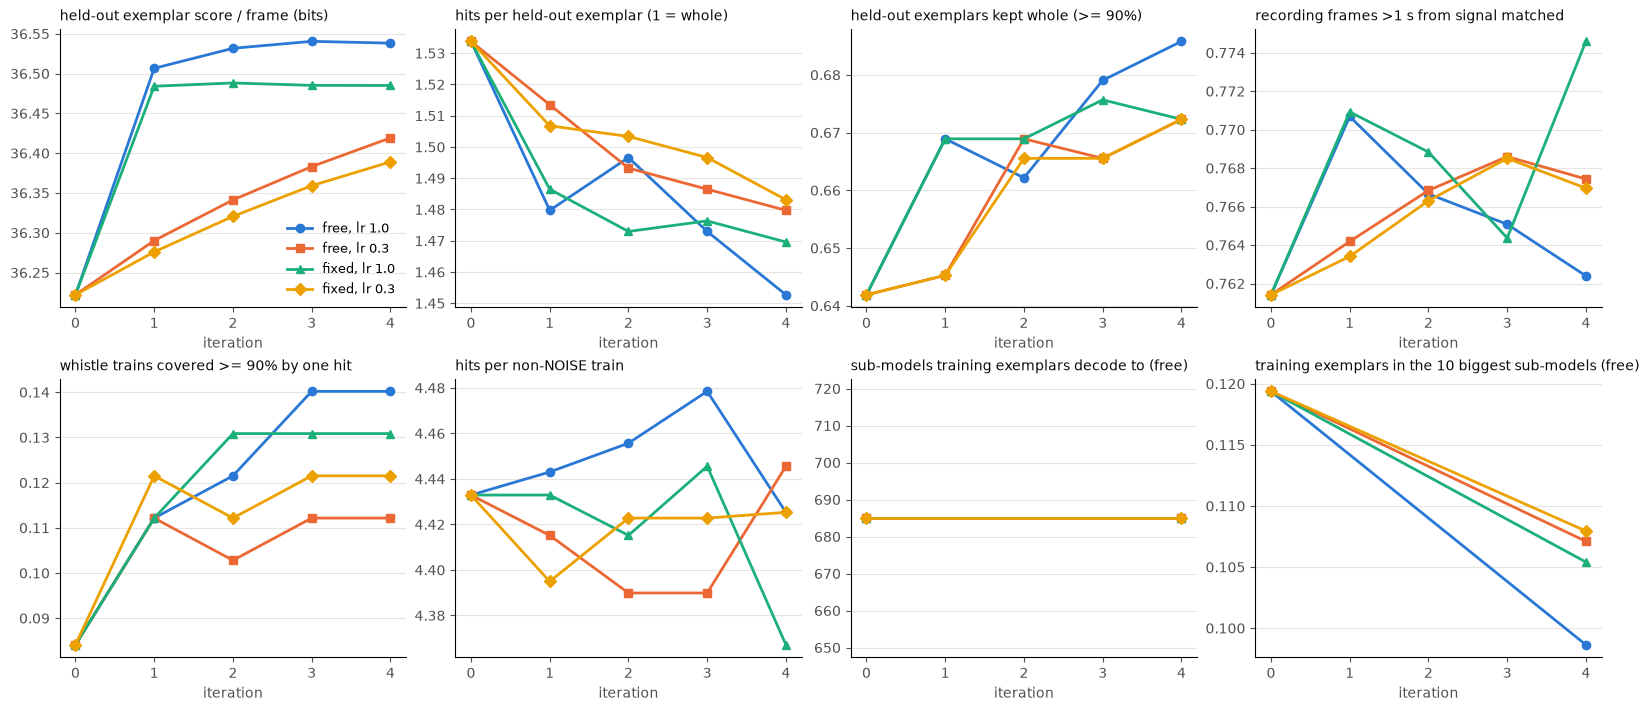

In [8]:
fig = plot_sweep(sweep, EXEMPLAR_PANELS)

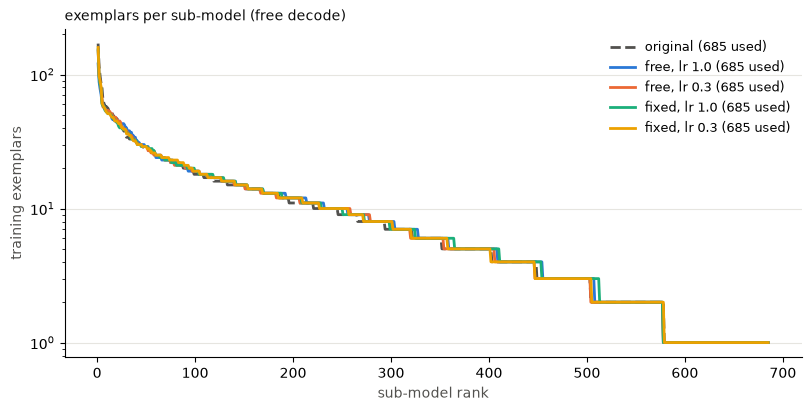

In [9]:
fig = plot_usage(usage)

## Before / after examples

The same held-out whistle trains decoded by the original model and a trained one, shown with the spectrogram, the classifier labels and each model's hits (labelled with sub-model id). Whistle trains are shaded light blue behind the hit rows. `pick_examples` takes the trains whose decode changed most, plus random ones.

In [10]:
EXAMPLE_CONFIG = "fixed, lr 0.3"   # which trained model to compare against the original

examples = pick_examples(
    (hmm, noise_pdf), (sweep_models[EXAMPLE_CONFIG], noise_pdf),
    heldout_sequences, heldout_labels, heldout_names,
    n_changed=4, n_random=2, window=300, max_candidates=40,
)

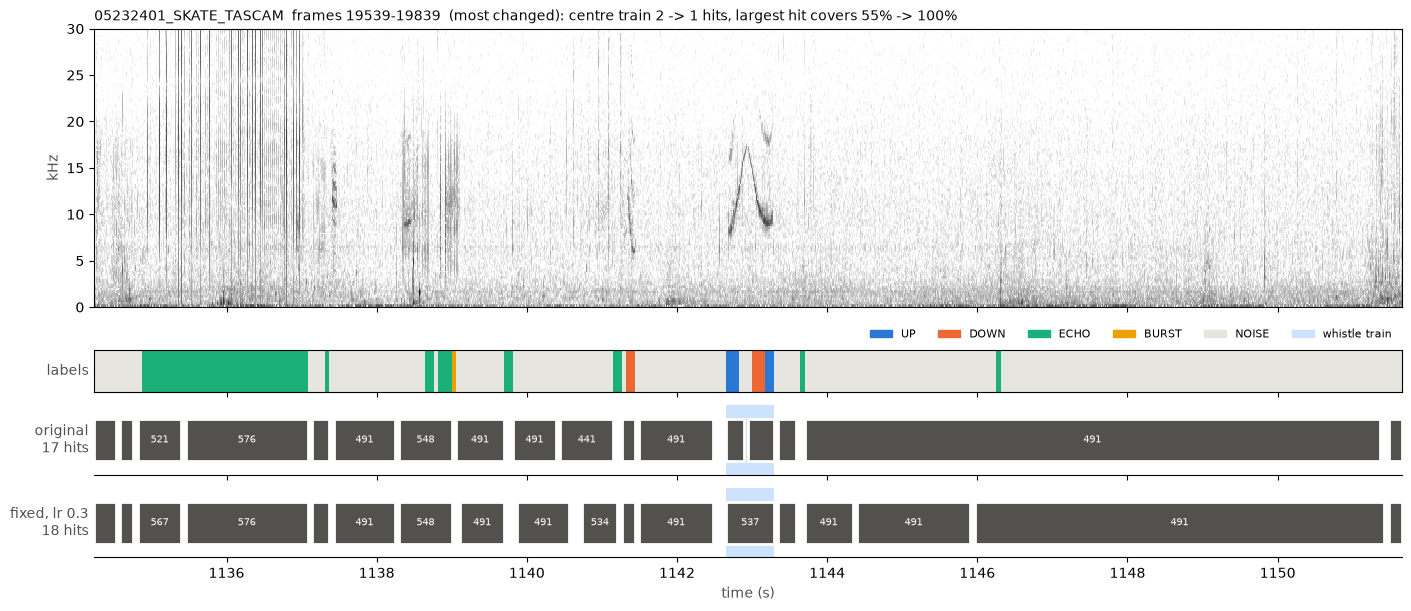

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,1134.24,1134.53,5,441,NOISE,1.00
1,before,1134.59,1134.76,3,462,NOISE,1.00
2,before,1134.82,1135.40,10,521,ECHO,0.90
3,before,1135.46,1137.08,28,576,ECHO,1.00
4,before,1137.14,1137.37,4,543,NOISE,0.75
5,before,1137.43,1138.24,14,491,NOISE,1.00
6,before,1138.30,1139.00,12,548,NOISE,0.58
7,before,1139.05,1139.69,11,491,NOISE,1.00
8,before,1139.81,1140.39,10,491,NOISE,1.00
9,before,1140.45,1141.14,12,441,NOISE,1.00


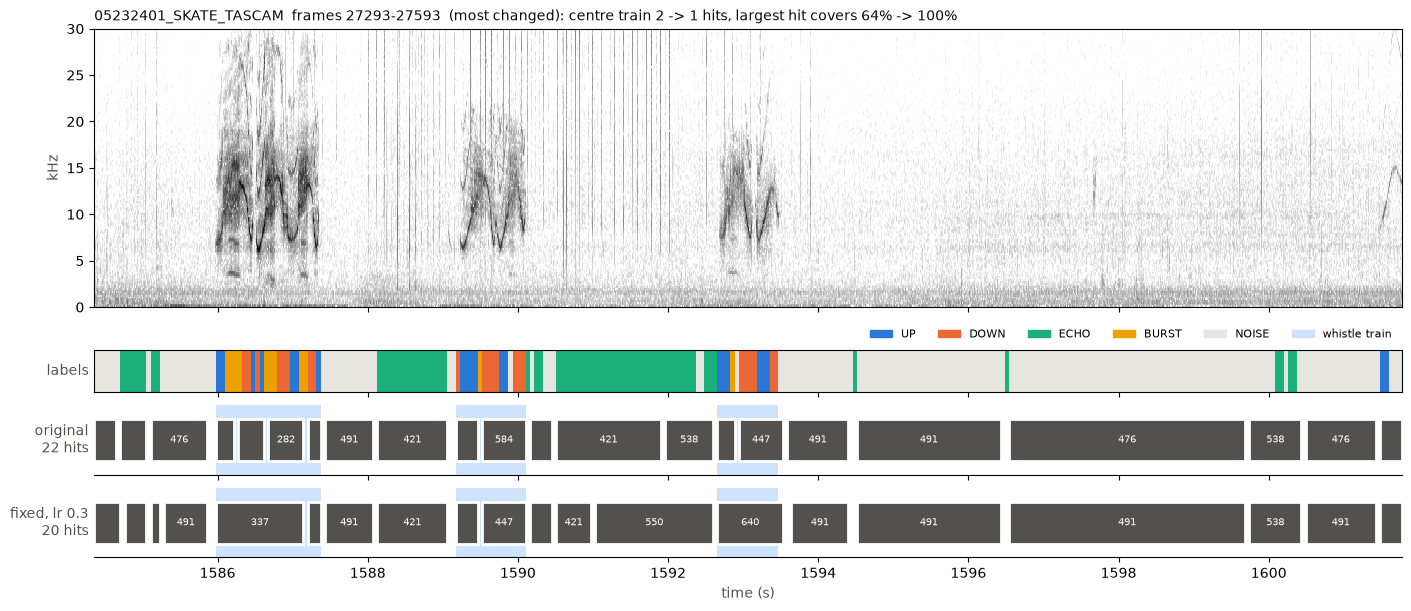

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,1584.36,1584.65,5,491,NOISE,1.00
1,before,1584.70,1585.05,6,483,ECHO,1.00
2,before,1585.11,1585.86,13,476,NOISE,0.85
3,before,1585.98,1586.21,4,355,UP,0.50
4,before,1586.27,1586.62,6,186,DOWN,0.50
5,before,1586.68,1587.14,8,282,BURST,0.38
6,before,1587.20,1587.37,3,584,DOWN,0.67
7,before,1587.43,1588.07,11,491,NOISE,1.00
8,before,1588.13,1589.06,16,421,ECHO,1.00
9,before,1589.17,1589.46,5,271,UP,0.80


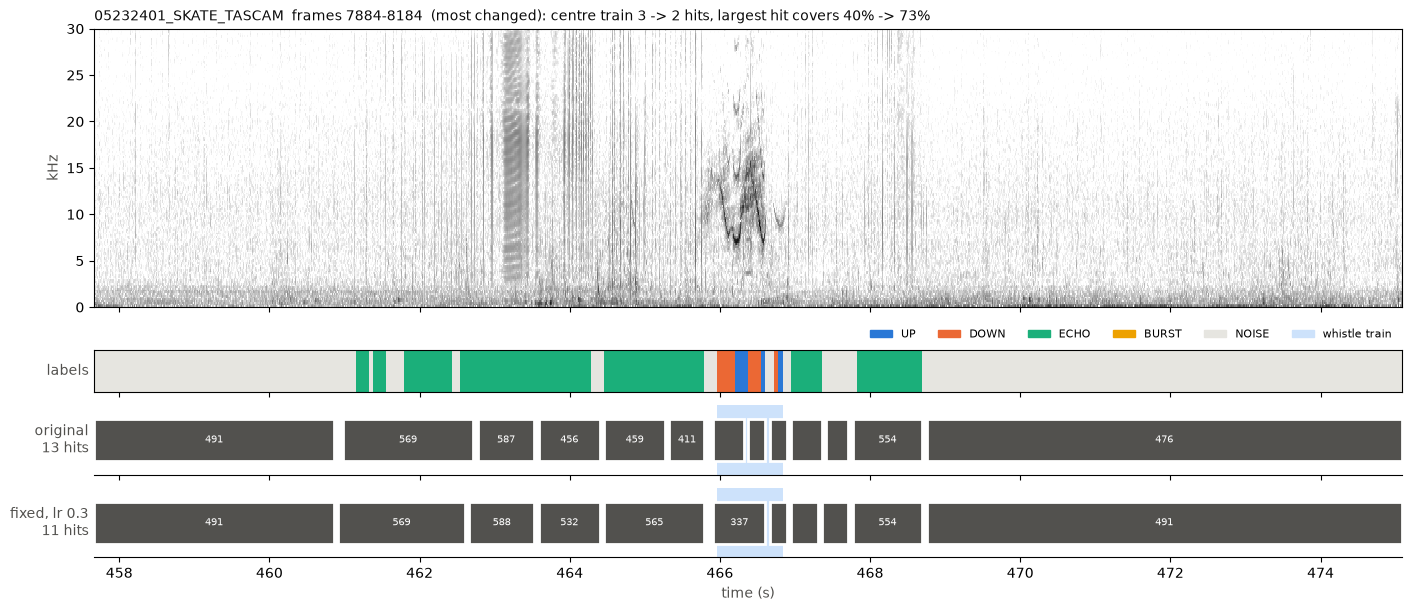

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,457.67,460.86,55,491,NOISE,1.00
1,before,460.97,462.72,30,569,ECHO,0.67
2,before,462.77,463.53,13,587,ECHO,1.00
3,before,463.59,464.40,14,456,ECHO,0.86
4,before,464.46,465.27,14,459,ECHO,1.00
5,before,465.33,465.79,8,411,ECHO,1.00
6,before,465.91,466.31,7,489,DOWN,0.57
7,before,466.37,466.60,4,489,DOWN,0.75
8,before,466.66,466.90,4,631,NOISE,0.50
9,before,466.95,467.36,7,421,ECHO,1.00


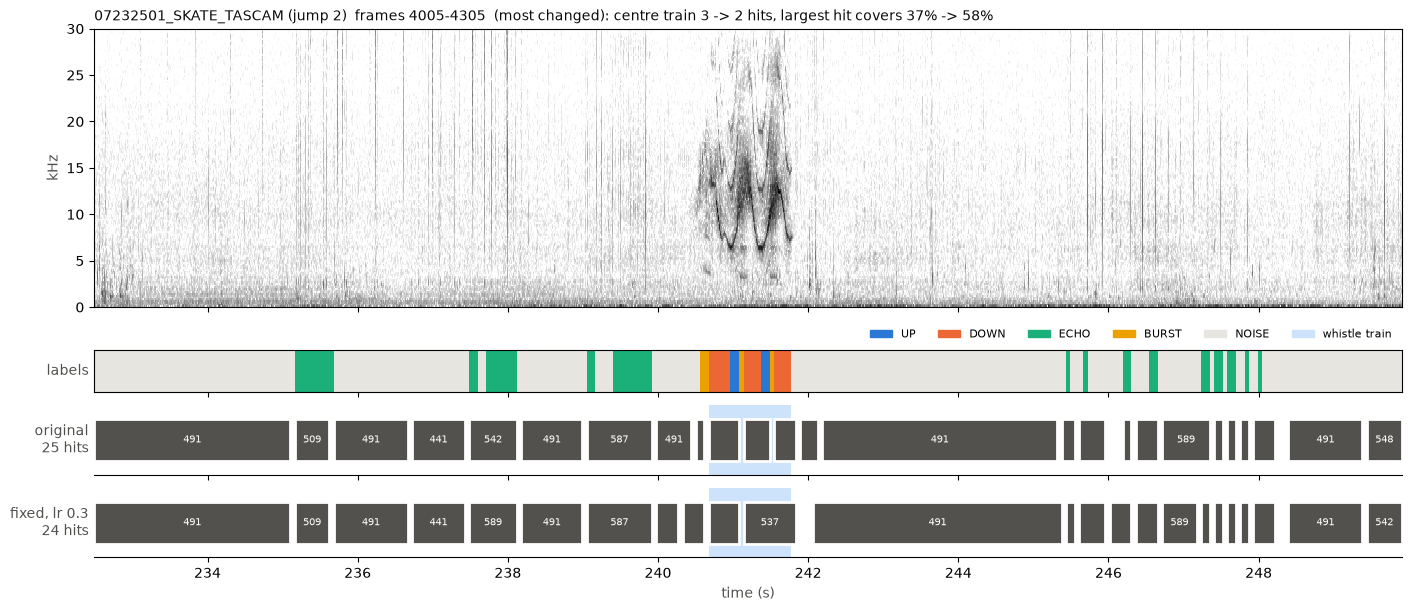

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,232.49,235.10,45,491,NOISE,1.00
1,before,235.16,235.62,8,509,ECHO,1.00
2,before,235.68,236.67,17,491,NOISE,1.00
3,before,236.73,237.42,12,441,NOISE,1.00
4,before,237.48,238.12,11,542,ECHO,0.82
5,before,238.18,238.99,14,491,NOISE,1.00
6,before,239.05,239.92,15,587,ECHO,0.73
7,before,239.98,240.44,8,491,NOISE,1.00
8,before,240.50,240.62,2,455,NOISE,0.50
9,before,240.67,241.08,7,447,DOWN,0.71


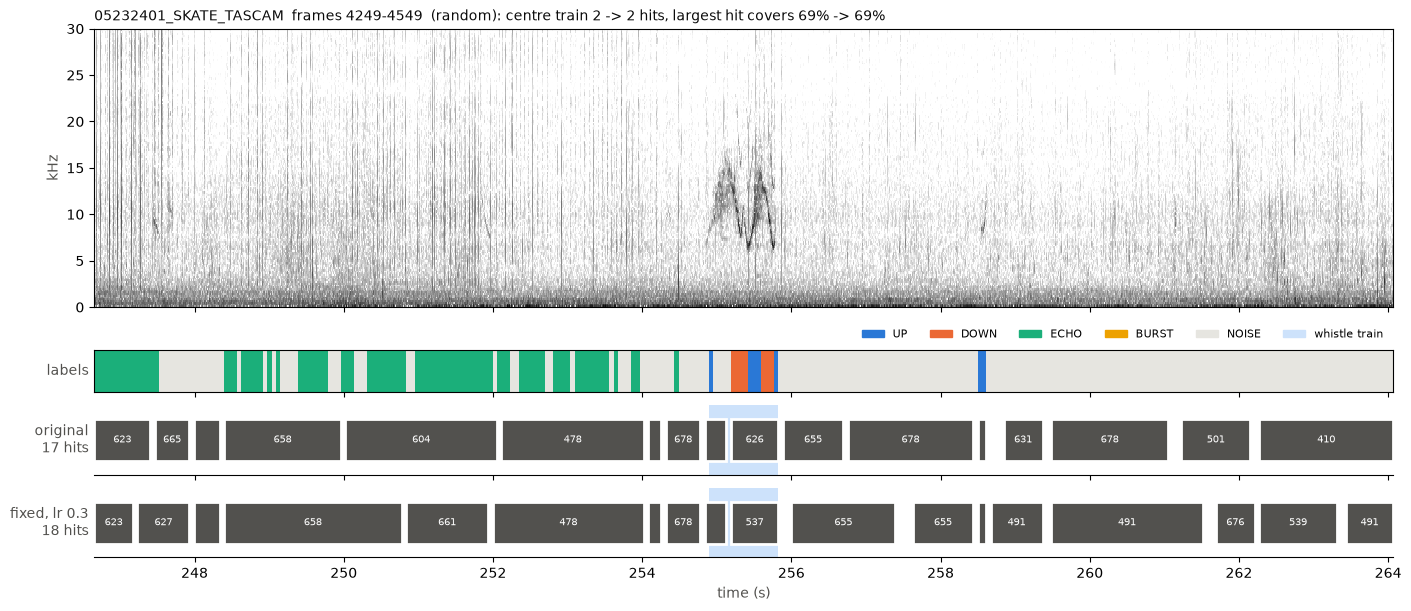

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,246.65,247.41,13,623,ECHO,1.00
1,before,247.47,247.93,8,665,NOISE,0.88
2,before,247.99,248.34,6,491,NOISE,1.00
3,before,248.40,249.96,27,658,ECHO,0.63
4,before,250.02,252.05,35,604,ECHO,0.83
5,before,252.11,254.03,33,478,ECHO,0.70
6,before,254.08,254.26,3,482,NOISE,1.00
7,before,254.32,254.78,8,678,NOISE,0.88
8,before,254.84,255.13,5,631,NOISE,0.80
9,before,255.19,255.83,11,626,DOWN,0.64


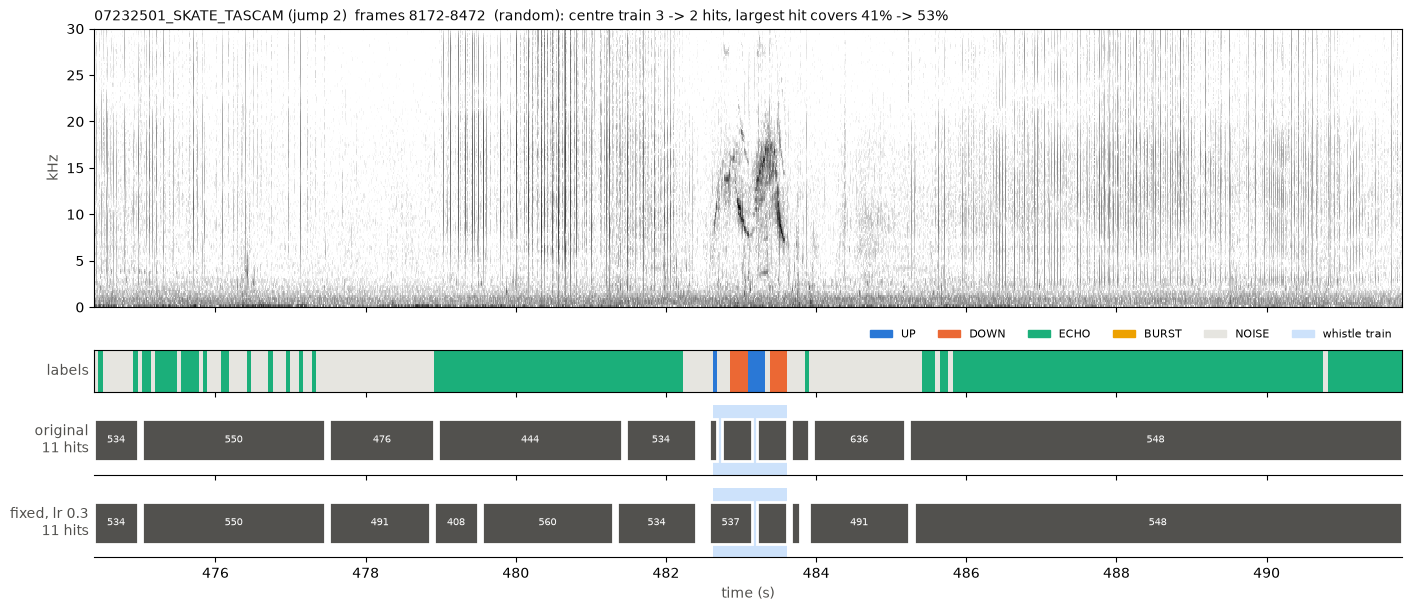

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,474.38,474.96,10,534,NOISE,0.80
1,before,475.02,477.46,42,550,NOISE,0.55
2,before,477.52,478.91,24,476,NOISE,1.00
3,before,478.97,481.41,42,444,ECHO,1.00
4,before,481.47,482.39,16,534,ECHO,0.81
5,before,482.57,482.68,2,596,NOISE,0.50
6,before,482.74,483.15,7,583,DOWN,0.57
7,before,483.21,483.61,7,640,DOWN,0.57
8,before,483.67,483.90,4,548,NOISE,0.75
9,before,483.96,485.18,21,636,NOISE,1.00


In [11]:
from IPython.display import display
import matplotlib.pyplot as plt

for ex in examples:
    plot_example(ex, STEP_SECONDS, audio_index.get(ex['name']), before_label="original",
                    after_label=EXAMPLE_CONFIG, fmax_hz=FMAX_HZ)
    plt.show()
    display(example_table(ex, STEP_SECONDS))

## How the whole-file decodes change

No labels and no accuracy here, just what changes when `find` decodes the held-out recordings with a trained model instead of the original one. Each recording is decoded whole, in the same 4,202-frame chunks as the evaluation, since a full file doesn't fit in memory.

- **Hits**: *hits_per_min*, *mean_hit_s* and *match_fraction* of each model's decode.
- **Frame agreement**: *frames_same_status* is the share of frames that are matched in both decodes or background in both. *matched_same_submodel* is the share of frames matched in both that keep their sub-model.
- **What happened to the original hits**: *hits_kept* means the same boundaries within 1 frame, whatever the sub-model. *hits_relabelled* means kept but with a different sub-model. *hits_split* means now covered by 2 or more hits. *hits_merged* is the share of the new decode's hits that each cover 2 or more original hits.
- **Sub-models**: *submodels_used* and *top10_share* over each decode's hits.

The original row compares the original decode with itself, as a reference.

In [12]:
import pandas as pd

_, CHUNK_FRAMES = plan_workers(hmm, n_jobs=4)
decodes = {"original": decode_recordings(hmm, noise_pdf, heldout_sequences, CHUNK_FRAMES)}
for name, trained_hmm in sweep_models.items():
    decodes[name] = decode_recordings(trained_hmm, noise_pdf, heldout_sequences, CHUNK_FRAMES)

decode_comparison = pd.DataFrame({name: decode_change(decodes["original"], d, STEP_SECONDS)
                                  for name, d in decodes.items()}).T
decode_comparison.round(3)

E-step: 4 workers x 4202-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


,hits_per_min,mean_hit_s,match_fraction,frames_same_status,matched_same_submodel,hits_kept,hits_relabelled,hits_split,hits_merged,submodels_used,top10_share
original,38.685,1.182,0.762,1.000,1.000,1.000,0.000,0.000,0.000,271.0,0.431
"free, lr 1.0",40.203,1.147,0.768,0.944,0.390,0.428,0.203,0.221,0.204,256.0,0.492
"free, lr 0.3",37.227,1.240,0.769,0.964,0.553,0.565,0.154,0.147,0.175,258.0,0.470
"fixed, lr 1.0",36.071,1.297,0.780,0.946,0.326,0.417,0.191,0.190,0.222,255.0,0.481
"fixed, lr 0.3",37.709,1.225,0.770,0.964,0.565,0.559,0.144,0.156,0.178,259.0,0.462


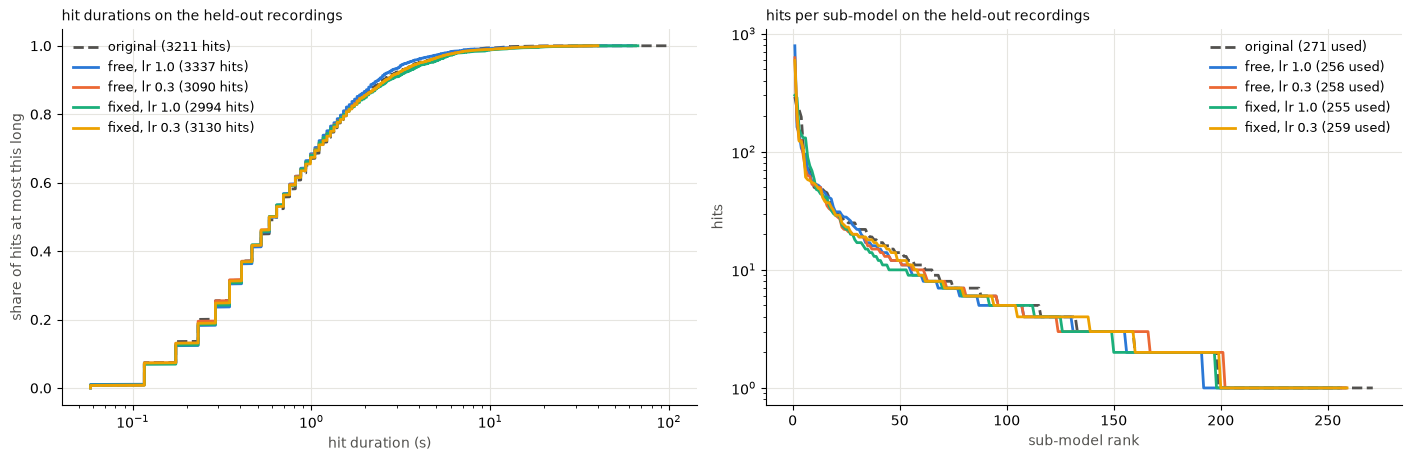

In [13]:
fig = plot_decode_change(decodes, STEP_SECONDS)

### Decoding plots from the whole-file decodes

The same plots as the before/after examples, but cut straight out of the whole-file decodes above, so they show exactly what changed when a full recording is decoded. They show the windows where the most frames changed status (match vs. background) or sub-model, plus random windows.

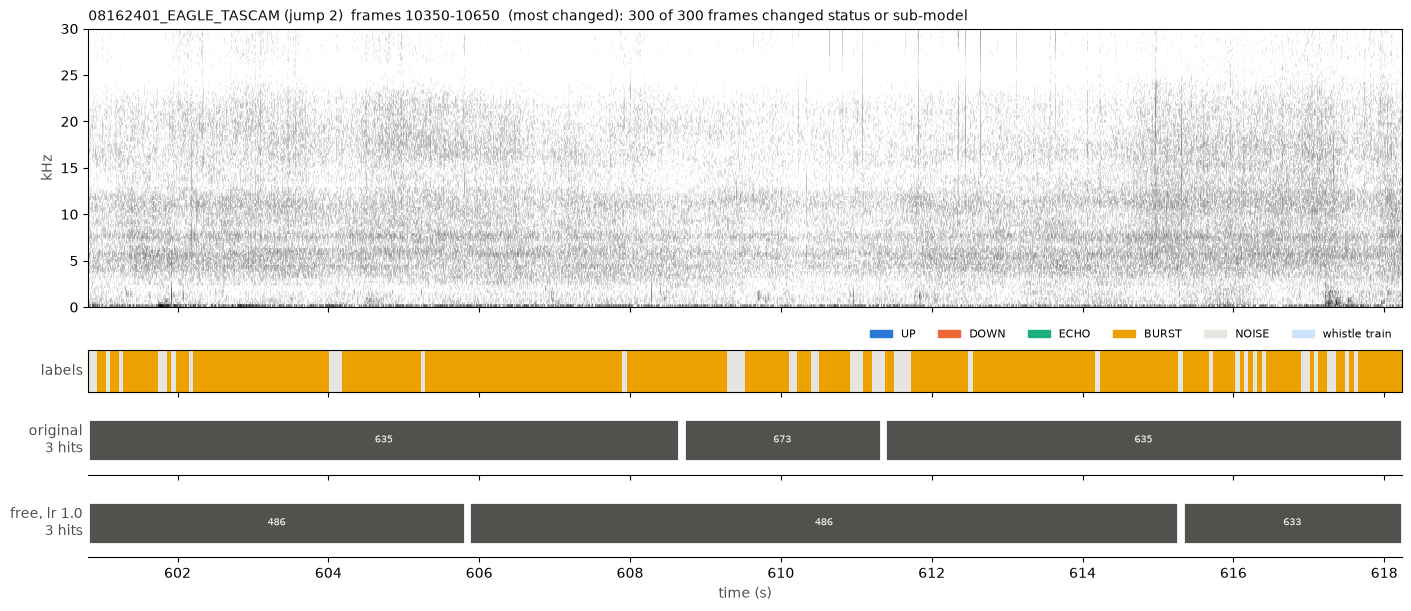

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,600.82,608.65,135,635,BURST,0.90
1,before,608.71,611.32,45,673,BURST,0.71
2,before,611.38,618.23,118,635,BURST,0.84
3,after,600.82,605.81,86,486,BURST,0.86
4,after,605.87,615.27,162,486,BURST,0.87
5,after,615.33,618.23,50,633,BURST,0.76


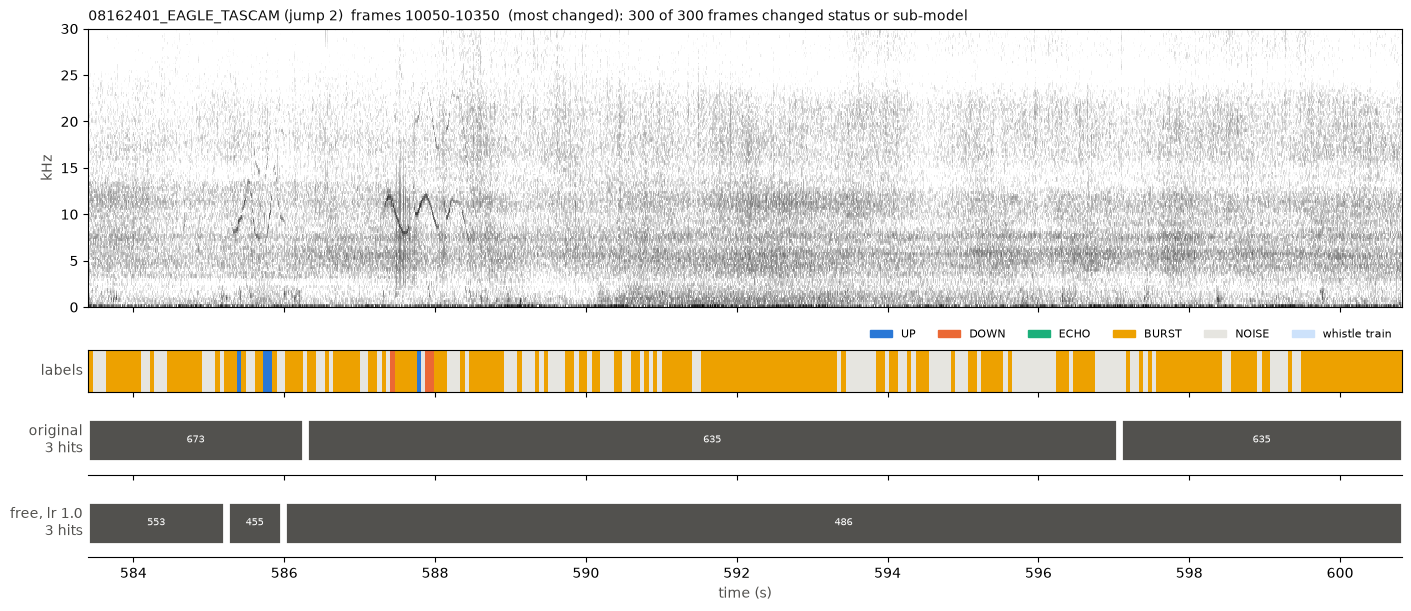

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,583.40,586.25,49,673,BURST,0.61
1,before,586.30,597.04,185,635,BURST,0.58
2,before,597.10,600.82,64,635,BURST,0.78
3,after,583.40,585.20,31,553,BURST,0.61
4,after,585.26,585.96,12,455,BURST,0.50
5,after,586.01,600.82,255,486,BURST,0.64


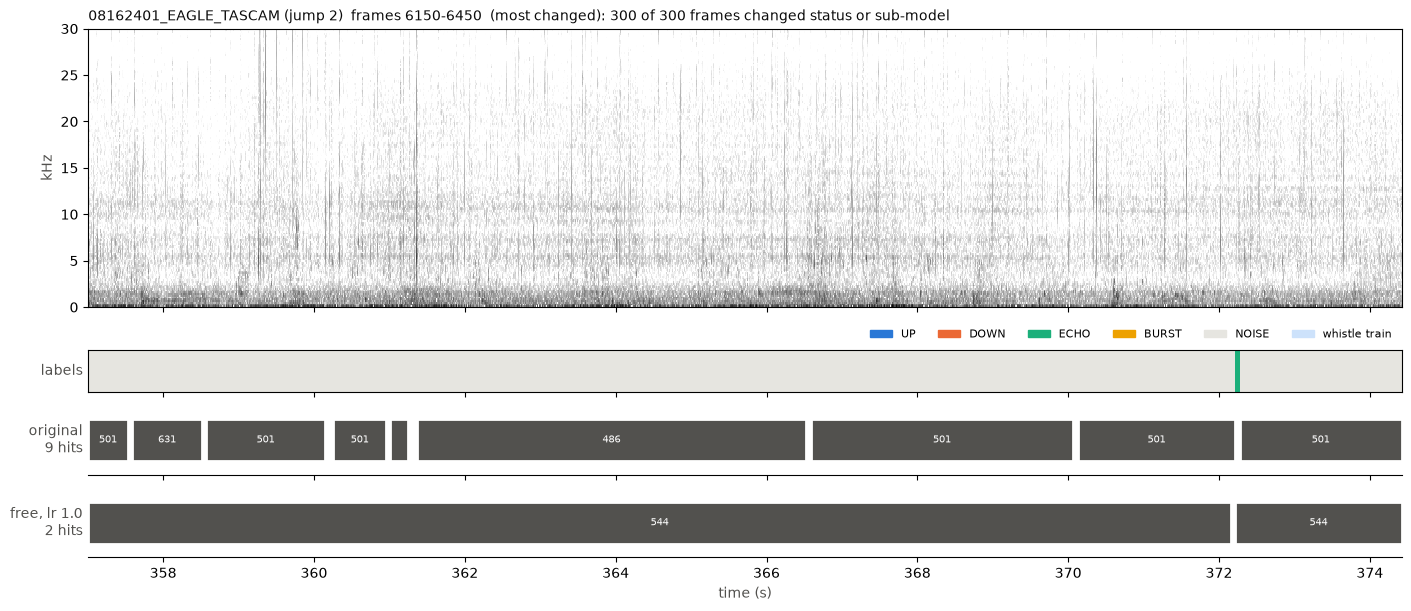

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,357.01,357.53,9,501,NOISE,1.00
1,before,357.59,358.52,16,631,NOISE,1.00
2,before,358.57,360.14,27,501,NOISE,1.00
3,before,360.26,360.95,12,501,NOISE,1.00
4,before,361.01,361.24,4,634,NOISE,1.00
5,before,361.36,366.53,89,486,NOISE,1.00
6,before,366.59,370.07,60,501,NOISE,1.00
7,before,370.13,372.22,36,501,NOISE,1.00
8,before,372.27,374.42,37,501,NOISE,1.00
9,after,357.01,372.16,261,544,NOISE,1.00


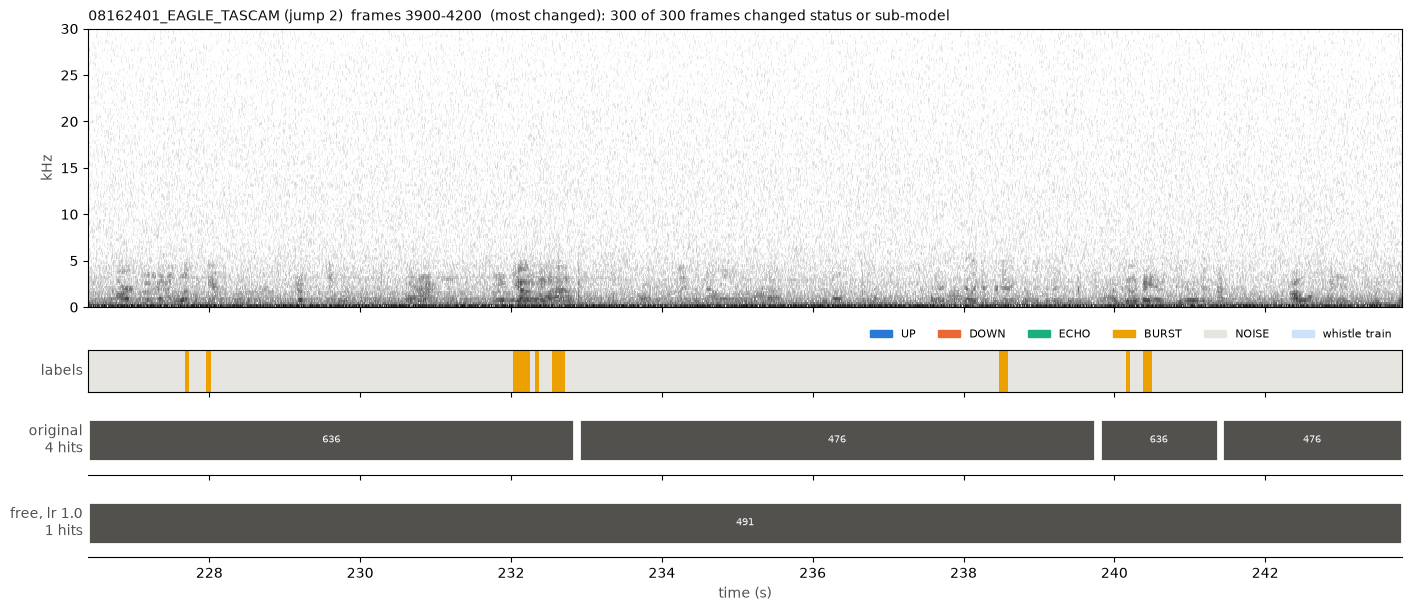

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,226.39,232.84,111,636,NOISE,0.91
1,before,232.90,239.75,118,476,NOISE,0.98
2,before,239.80,241.37,27,636,NOISE,0.89
3,before,241.43,243.81,41,476,NOISE,1.00
4,after,226.39,243.81,300,491,NOISE,0.95


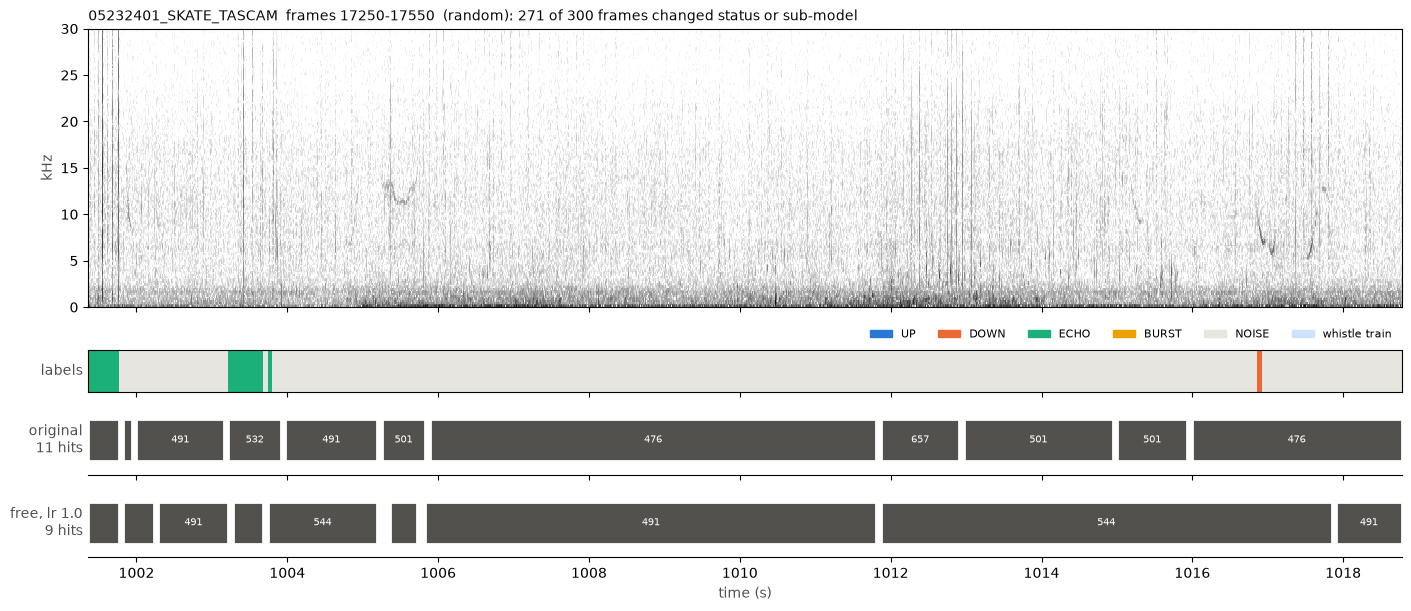

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,1001.36,1001.77,7,483,ECHO,1.00
1,before,1001.82,1001.94,2,455,NOISE,1.00
2,before,1002.00,1003.16,20,491,NOISE,1.00
3,before,1003.22,1003.91,12,532,ECHO,0.75
4,before,1003.97,1005.19,21,491,NOISE,1.00
5,before,1005.25,1005.83,10,501,NOISE,1.00
6,before,1005.89,1011.81,102,476,NOISE,1.00
7,before,1011.87,1012.91,18,657,NOISE,1.00
8,before,1012.97,1014.94,34,501,NOISE,1.00
9,before,1015.00,1015.93,16,501,NOISE,1.00


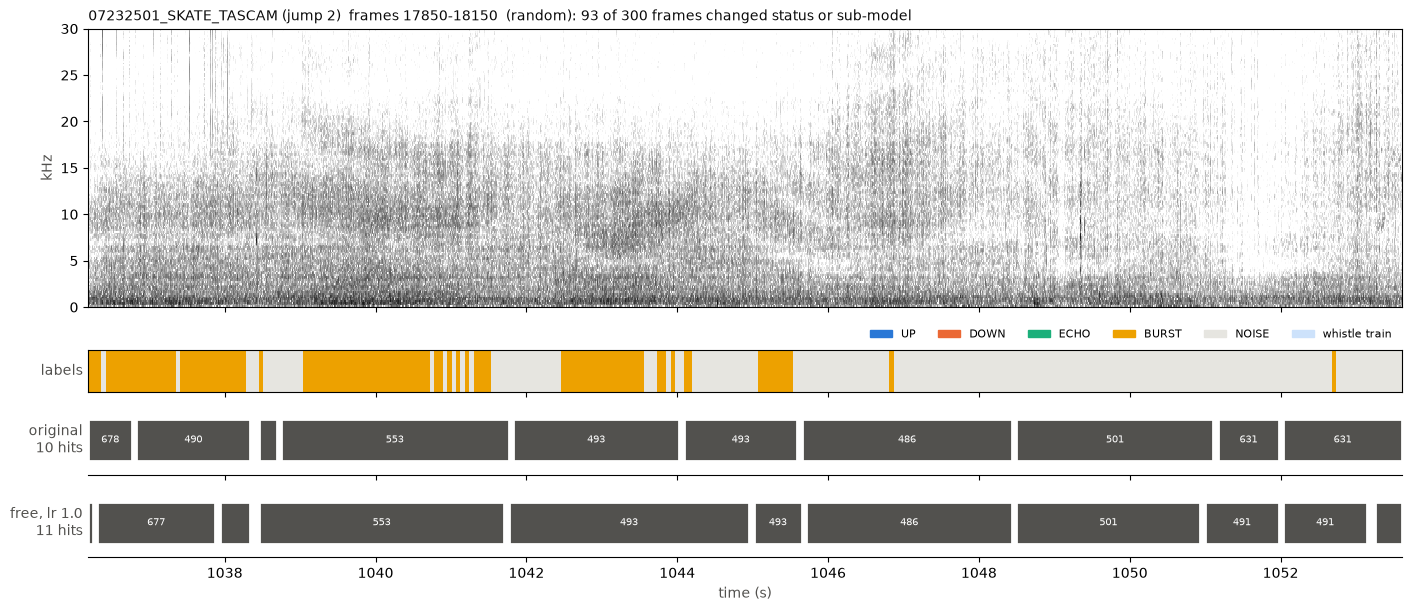

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,1036.19,1036.77,10,678,BURST,0.90
1,before,1036.83,1038.34,26,490,BURST,0.92
2,before,1038.45,1038.69,4,493,NOISE,0.75
3,before,1038.74,1041.76,52,553,BURST,0.73
4,before,1041.82,1044.03,38,493,BURST,0.58
5,before,1044.09,1045.59,26,493,NOISE,0.62
6,before,1045.65,1048.44,48,486,NOISE,0.98
7,before,1048.50,1051.11,45,501,NOISE,1.00
8,before,1051.17,1051.98,14,631,NOISE,1.00
9,before,1052.04,1053.61,27,631,NOISE,0.96


In [14]:
DECODE_EXAMPLE_CONFIG = "free, lr 1.0"   # which trained model's whole-file decode to compare with the original

decode_examples = pick_decode_windows(decodes["original"], decodes[DECODE_EXAMPLE_CONFIG], heldout_labels, heldout_names,
                                      window=300, n_changed=4, n_random=2)
for ex in decode_examples:
    plot_example(ex, STEP_SECONDS, audio_index.get(ex['name']), before_label="original",
                 after_label=DECODE_EXAMPLE_CONFIG, fmax_hz=FMAX_HZ)
    plt.show()
    display(example_table(ex, STEP_SECONDS))